# Discovery of tissue macro-niches through joint analysis of HnE and Xenium data

In [1]:
import sys 
import os
from datetime import datetime
today = datetime.now().strftime("%Y-%m-%d")

import anndata as ad
import hdf5plugin
import squidpy as sq
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from spatialdata_io.readers.xenium import xenium_aligned_image
import spatialdata as sd
import rapids_singlecell as rsc

import warnings
warnings.filterwarnings('ignore', category=ad.ImplicitModificationWarning)

# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path,_ = os.path.split(os.path.split(os.getcwd())[0])
repo_path = '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses'
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/scripts')
sys.path.insert(3, '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts')

# Autoreload custom scripts
%load_ext autoreload
%autoreload 2

# Define paths
plots_path = f'{repo_path}/plots/'
data_path = f'{repo_path}/data/'
model_path = os.path.join(repo_path, 'models')
general_data_path = '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/data/'

print('Dir for plots: {}'.format(plots_path))
print('Dir for data: {}'.format(data_path))

# Formatting
from matplotlib import font_manager
font_manager.fontManager.addfont("/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf")
plt.style.use('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing.mplstyle')

from plotting.utils import calc_figsize, thyAgeing_greys, thyAgeing_colors

Dir for plots: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots/
Dir for data: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/data/


In [2]:
# Load general and HnE metadata
from utils import get_latest_version,update_obs
latest_meta_path = get_latest_version(dir = f'{general_data_path}/metadata', file_prefix='Thymus_ageing_metadata')
latest_meta = pd.read_excel(latest_meta_path)

he_meta = pd.read_csv('/lustre/scratch126/cellgen/teichmann/lm25/data/thymus_he/thyAgeing_HnE.csv')
he_meta = he_meta.merge(latest_meta[['donor', 'sex', 'age_group']].drop_duplicates(), left_on = 'DonorID', right_on = 'donor', how = 'left').drop('donor', axis = 1)
he_meta['SampleID'] = he_meta['file_name'].str.split(' - ').str[0]
he_meta.head()

Latest file: Thymus_ageing_metadata_v30_2026-07-09.xlsx


,file_name,image_id,DonorID,tissue_embedding,resolution,dimensions,n_slices,info_slices,format,annotation_file,has_xenium,source,file_path,sex,age_group,SampleID
0,U48-THY-0-FFPE-1-S7-i_S000005312 - 2025-01-10 ...,75701.0,U48,FFPE,0.227,45056 x 48384,1,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,M,infant,U48-THY-0-FFPE-1-S7-i_S000005312
1,U40-THY-0-FFPE-1-S18-i_S000005306 - 2025-01-10...,75698.0,U40,FFPE,0.227,49152 x 35840,1,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,F,infant,U40-THY-0-FFPE-1-S18-i_S000005306
2,Z11-THY-0-FFPE-1-S1i_S5297 - 2024-12-19 09.00.52,75347.0,Z11,FFPE,0.227,28672 x 30464,1,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,F,infant,Z11-THY-0-FFPE-1-S1i_S5297
3,Z12-THY-0-FFPE-1-S2ii_S5298 - 2024-12-19 09.03.17,75350.0,Z12,FFPE,0.227,20480 x 27904,1,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,M,paed,Z12-THY-0-FFPE-1-S2ii_S5298
4,A45-THY-0-FFPE-1 - 2024-10-15 16.55.54,69701.0,A45,FFPE,0.227,61440 x 64000,3,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,M,adult,A45-THY-0-FFPE-1


## Leiden clustering of integrated HnE data

In [ ]:
# Load integrated HnE data
he_adata = ad.read_h5ad(f'{data_path}/morphoFM/thyAging_CAM_morphoFM_mpp025_mf2_he_coral.h5ad')

In [ ]:
rsc.get.anndata_to_GPU(he_adata)
for res in [0.5, 1.0, 2.0, 3.0]:
    rsc.tl.leiden(he_adata, resolution=res, key_added=f'leiden_r{res}')
    
    
with plt.rc_context({'figure.figsize' : calc_figsize(width = 270, height = 180)}):
    sc.pl.umap(he_adata, color = [f'leiden_r{res}' for res in [0.5, 1.0, 2.0, 3.0]], legend_fontsize = 10, ncols = 2, wspace=0.3, return_fig = True, show = False)
    plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAgeing_bbknn_umap_clusters.png', bbox_inches='tight', dpi = 300)

Width exceeds the maximum width of 183 mm


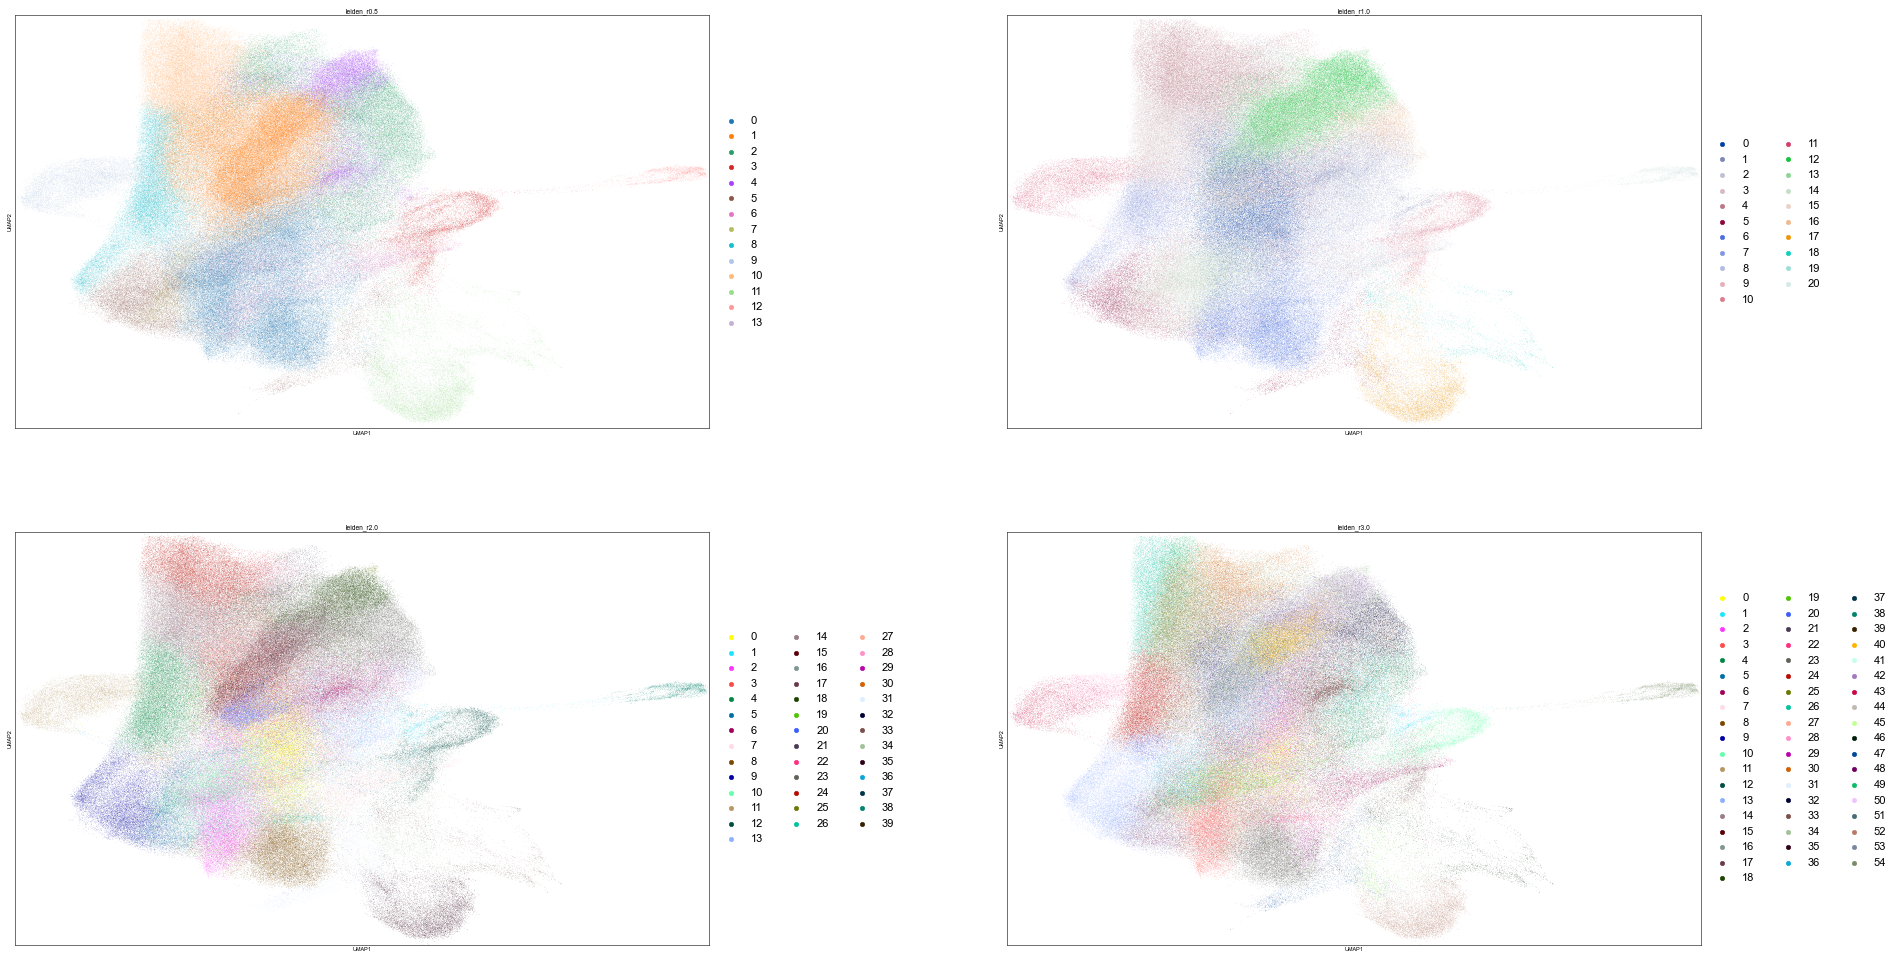

In [6]:
plt.show()

In [ ]:
import seaborn as sns
qc_cols = ['tissue_fraction', 'valid_tissue_fraction', 'saturation_fraction', 'dark_fraction', 'gray_std']

plt.figure(figsize=calc_figsize(width = 180, height = 270))
g = sns.FacetGrid(he_adata.obs.melt(id_vars='leiden_r2.0', value_vars=qc_cols), 
                    col='variable', col_wrap=1, sharey=False, height=4, aspect=2)
g.map_dataframe(sns.violinplot, x='leiden_r2.0', y='value', hue='leiden_r2.0', split=False, 
                palette=he_adata.uns['leiden_r2.0_colors'], inner=None)
g.add_legend()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAgeing_leiden_r2.0_qc_violin.png', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
# Heatmap of patch counts per sample and niche
plot_data = he_adata.obs.groupby(['leiden_r2.0', 'SampleID']).size().to_frame('count').pivot_table(index='SampleID', columns='leiden_r2.0', values='count', fill_value=0)
plot_data.to_csv(f'{data_path}/morpho_niches/thyAgeing_leiden_r2.0_patch_counts_per_sample.csv')

plot_data.replace(0, np.nan, inplace=True)  # Replace 0 with NaN for better visualization in heatmap
plot_data=plot_data.applymap(lambda x: np.log10(x))  # Apply log transformation for better visualization

plt.figure(figsize=calc_figsize(width = 220, height = 180))
sns.heatmap(plot_data, annot=True, annot_kws={"size": 5}, cbar_kws={'label': 'Log10(Patch Count)'}, linewidths=0.5, linecolor='gray')
plt.title('Patch Counts per Sample and Niche')
plt.xlabel('Leiden r2.0')
plt.ylabel('Sample')
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAgeing_leiden_r2.0_patch_counts_per_sample.pdf', bbox_inches='tight', dpi=300)

In [ ]:
# Calculate gini coefficient per cluster based on donor contributions
gini_coeffs = []

for cluster in he_adata.obs['leiden_r2.0'].cat.categories:
    cluster_data = he_adata.obs[he_adata.obs['leiden_r2.0'] == cluster]
    donor_counts = cluster_data['DonorID'].value_counts()
    sample_counts = cluster_data['SampleID'].value_counts()
    total_patches = donor_counts.sum()
    
    # Calculate Gini coefficient
    if total_patches > 0:
        sorted_counts = donor_counts.sort_values()
        n = len(sorted_counts)
        cumulative_counts = np.cumsum(sorted_counts)
        donor_gini = (n + 1 - 2 * np.sum(cumulative_counts) / total_patches) / n
        
        sorted_counts = sample_counts.sort_values()
        n = len(sample_counts)
        cumulative_counts = np.cumsum(sorted_counts)
        sample_gini = (n + 1 - 2 * np.sum(cumulative_counts) / total_patches) / n
        
    else:
        donor_gini = np.nan  # Handle case with no patches
        sample_gini = np.nan  # Handle case with no patches
    
    gini_coeffs.append({'cluster': cluster, 'gini_donor': donor_gini, 'gini_sample': sample_gini})

gini_df = pd.DataFrame(gini_coeffs)

fig, axes = plt.subplots(
    3, 1,
    figsize=calc_figsize(width=180, height=120),
    sharex=True
)

cluster_order = he_adata.obs['leiden_r2.0'].cat.categories.tolist()

sns.barplot(
    data=gini_df,
    x='cluster',
    y='gini_sample',
    order=cluster_order,
    hue='cluster',
    palette=he_adata.uns['leiden_r2.0_colors'],
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Gini Coefficient of Donor Contributions per Cluster')
axes[0].set_xlabel('Leiden r2.0 Cluster')
axes[0].set_ylabel('Gini Coefficient')

sns.barplot(
    data=gini_df,
    x='cluster',
    y='gini_donor',
    order=cluster_order,
    hue='cluster',
    palette=he_adata.uns['leiden_r2.0_colors'],
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Gini Coefficient of Donor Contributions per Cluster')
axes[1].set_xlabel('Leiden r2.0 Cluster')
axes[1].set_ylabel('Gini Coefficient')

# Add barplot for number of donors per cluster
n_donors_df = he_adata.obs.groupby('leiden_r2.0')['DonorID'].nunique().reset_index()
n_donors_df.columns = ['cluster', 'n_donors']

sns.barplot(
    data=n_donors_df,
    x='cluster',
    y='n_donors',
    order=cluster_order,
    hue='cluster',
    palette=he_adata.uns['leiden_r2.0_colors'],
    legend=False,
    ax=axes[2]
)
axes[2].set_title('Number of Donors per Cluster')
axes[2].set_xlabel('Leiden r2.0 Cluster')
axes[2].set_ylabel('Number of Donors')
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAgeing_leiden_r2.0_gini_sample_donor.pdf', bbox_inches='tight', dpi=300)

In [ ]:
# Transfer to CPU for saving and downstream analysis
rsc.get.anndata_to_CPU(he_adata)
he_adata.write_h5ad(f'{data_path}/morphoFM/thyAging_CAM_morphoFM_mpp025_mf2_he_coral.h5ad')

### Export cluster annotations as geojson

In [36]:
import tifffile
import numpy as np
import json
import numpy as np
import matplotlib.cm as cm

def tiles_to_original_coords(tiles_df, orig_mpp, target_mpp=0.25):
    """
    Map tile boxes (in the resampled mpp-image space) back to original
    level-0 WSI pixel coordinates.

    resampled = original * scale, with scale = orig_mpp / target_mpp
      => original = resampled / scale = resampled * (target_mpp / orig_mpp)
    """
    # Matches resample_to_target_mpp: if orig ~= target, no resampling was done.
    if abs(orig_mpp - target_mpp) <= 1e-4:
        inv_scale = 1.0
    else:
        scale = orig_mpp / target_mpp
        inv_scale = 1.0 / scale          # = target_mpp / orig_mpp

    out = tiles_df.copy()
    for col in ["x0", "x1", "y0", "y1", "cx_img", "cy_img"]:
        if col in out.columns:
            out[col + "_orig"] = out[col] * inv_scale

    return out, orig_mpp, inv_scale

from matplotlib.colors import to_rgb

def color_to_rgb255(c):
    """Any matplotlib color (hex, name, rgb tuple) -> [r, g, b] ints 0-255 for QuPath."""
    r, g, b = to_rgb(c)                       # floats 0..1
    return [int(round(r * 255)), int(round(g * 255)), int(round(b * 255))]


def export_niches_to_geojson(he_adata, sample, niche_col, orig_mpp, palette, out_dir = f"{data_path}/morpho_niches"):
    """
    Export the patches of a given sample to a GeoJSON file with their niche classification.
    
    Parameters:
    - he_adata: AnnData object containing the data.
    - sample: Sample ID to filter the data.
    - niche_col: Column name in he_adata.obs that contains the niche classification.
    - orig_mpp: Original microns per pixel value.
    - palette: Dictionary mapping niche labels to colors.
    """

    obs = he_adata.obs[he_adata.obs['SampleID'] == sample].copy()
    obs = tiles_to_original_coords(obs, orig_mpp)[0]
    
    x0 = np.round(obs["x0_orig"].to_numpy()).astype(int)
    x1 = np.round(obs["x1_orig"].to_numpy()).astype(int)
    y0 = np.round(obs["y0_orig"].to_numpy()).astype(int)
    y1 = np.round(obs["y1_orig"].to_numpy()).astype(int)

    label_col = niche_col
    cats = list(obs[label_col].cat.categories)
    codes = obs[label_col].cat.codes.to_numpy()       # int per patch, -1 if NaN
    labels = obs[label_col].astype(str).to_numpy()

    features = []
    for i in range(len(obs)):
        a, b, c, d = float(x0[i]), float(x1[i]), float(y0[i]), float(y1[i])
        ring = [[a, c], [b, c], [b, d], [a, d], [a, c]]   # closed, CW
        features.append({
            "type": "Feature",
            "geometry": {"type": "Polygon", "coordinates": [ring]},
            "properties": {
                "objectType": "annotation",
                "classification": {"name": labels[i], "color": color_to_rgb255(palette[labels[i]])},
            },
        })

    fc = {"type": "FeatureCollection", "features": features}
    with open(f"{out_dir}/{sample}_{niche_col}_qupath.geojson", "w") as f:
        json.dump(fc, f)
    print(len(features), "patches written")


In [5]:
xenium_samples = he_meta.loc[he_meta['has_xenium'] == True]['SampleID'].unique()
for sample in xenium_samples:
    niche_col = 'leiden_r2.0'
    orig_mpp = he_meta[he_meta['SampleID'] == sample]['resolution'].values[0]
    palette = dict(zip(he_adata.obs[niche_col].cat.categories, he_adata.uns[f'{niche_col}_colors']))

    export_niches_to_geojson(he_adata, sample, niche_col, orig_mpp, palette)

12324 patches written
20129 patches written
23494 patches written
3627 patches written
7572 patches written
15760 patches written
12924 patches written
18023 patches written


In [12]:
for sample in he_meta['SampleID'].unique():
    niche_col = 'leiden_r2.0'
    orig_mpp = he_meta[he_meta['SampleID'] == sample]['resolution'].values[0]
    palette = dict(zip(he_adata.obs[niche_col].cat.categories, he_adata.uns[f'{niche_col}_colors']))

    export_niches_to_geojson(he_adata, sample, niche_col, orig_mpp, palette)

9080 patches written
12884 patches written
3594 patches written
2810 patches written
25236 patches written
14074 patches written
16404 patches written
23238 patches written
0 patches written
0 patches written
6003 patches written
0 patches written
0 patches written
0 patches written
0 patches written
0 patches written
0 patches written
9435 patches written
0 patches written
0 patches written
0 patches written
0 patches written
0 patches written
21863 patches written
14300 patches written
17874 patches written
8147 patches written
14563 patches written
0 patches written
5059 patches written
26759 patches written
19723 patches written
18554 patches written
0 patches written
11537 patches written
4184 patches written
3921 patches written
4883 patches written
0 patches written
0 patches written
0 patches written
7200 patches written
12324 patches written
20129 patches written
23494 patches written
3627 patches written
7572 patches written
15760 patches written
12924 patches written
0 patch

In [11]:
from scripts.morpho.preprocess_morpho import overlay_clusters_on_slide

In [14]:
sample = 'U51.ome'
tiff_path, orig_mpp = he_meta.loc[he_meta['SampleID'] == sample, ['file_path', 'resolution']].values[0]
clusters = "2"
    
out, palette = overlay_clusters_on_slide(
    he_adata,
    sample=sample,
    tiff_path=tiff_path,
    orig_mpp=orig_mpp,
    clusters=clusters,
    label_col="leiden_r2.0",
    palette="uns",             # uses he_adata.uns["leiden_m2_r0.5_colors"]
    out_path=f"{plots_path}/morpho_niches2/niche_overlays/overlay_clusters_{clusters}_{sample}.png"
)


level 5 shape: (1489, 949, 3), scale x,y: 0.031236, 0.031234
Sample U51.ome: painted 3005/12924 patches for clusters ['2']
✅ Saved cluster overlay: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots/morpho_niches2/niche_overlays/overlay_clusters_2_U51.ome.png


In [ ]:
clusters_oi = [1,2,3,6,14,15,16,17,19,23,24,29,30,31,32,33,34,35,36,37,38,39,40,41]
clusters_oi_df = he_adata.obs[he_adata.obs['leiden_r2.0'].isin([str(c) for c in clusters_oi])]

clusters_oi_df.groupby(['leiden_r2.0', 'SampleID'], observed=True).size().to_frame('count').reset_index().to_csv(f'{data_path}/morpho_niches/thyAgeing_leiden_r2.0_patch_counts_per_sample_clusters_oi.csv', index = False)

In [15]:
contrib = (
    clusters_oi_df.groupby(['leiden_r2.0', 'SampleID'], observed=True)
    .size()
    .reset_index(name='n_patches')
)

top_donor_per_cluster = contrib.loc[
    contrib.groupby('leiden_r2.0', observed=True)['n_patches'].idxmax()
].sort_values('leiden_r2.0')

top_donor_per_cluster['pct_within_cluster'] = (
    top_donor_per_cluster['n_patches']
    / top_donor_per_cluster['leiden_r2.0'].map(contrib.groupby('leiden_r2.0')['n_patches'].sum())
    * 100
)

top_donor_per_cluster

,leiden_r2.0,SampleID,n_patches,pct_within_cluster
29,1,Z13-THY--FF-1,1401,26.989019
45,2,A72-THY-0-FFPE-1,3920,38.942976
81,3,U48-THY-0-FFPE-1-S7-i_S000005312,6347,47.401046
92,6,A53-THY-0-FF-2,1754,11.904439
129,14,A70.ome,701,40.057143
159,15,A70-THY-0-FFPE-2,3406,16.264744
187,16,A70-THY-0-FFPE-2,2188,20.951834
218,17,A70-THY-0-FFPE-3,1086,16.777383
238,19,A45.ome,271,17.054751
282,23,A74-THY-0-FFPE-1,3067,72.574539


In [17]:
os.makedirs(f"{plots_path}/morpho_niches2/niche_overlays", exist_ok=True)

for _, row in top_donor_per_cluster.iterrows():
    sample = row["SampleID"]
    cluster = str(row["leiden_r2.0"])

    tiff_path, orig_mpp = he_meta.loc[
        he_meta["SampleID"] == sample, ["file_path", "resolution"]
    ].values[0]

    out, palette = overlay_clusters_on_slide(
        he_adata,
        sample=sample,
        tiff_path=tiff_path,
        orig_mpp=orig_mpp,
        clusters=cluster,
        label_col="leiden_r2.0",
        palette="uns",
        out_path=f"{plots_path}/morpho_niches2/niche_overlays/overlay_clusters_{cluster}_{sample}.png",
    )

level 5 shape: (776, 2688, 3), scale x,y: 0.031250, 0.031250
Sample Z13-THY--FF-1: painted 1401/7200 patches for clusters ['1']
✅ Saved cluster overlay: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots/morpho_niches2/niche_overlays/overlay_clusters_1_Z13-THY--FF-1.png
level 5 shape: (1840, 1664, 3), scale x,y: 0.031250, 0.031250
Sample A72-THY-0-FFPE-1: painted 3920/21863 patches for clusters ['2']
✅ Saved cluster overlay: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots/morpho_niches2/niche_overlays/overlay_clusters_2_A72-THY-0-FFPE-1.png
level 5 shape: (1512, 1408, 3), scale x,y: 0.031250, 0.031250
Sample U48-THY-0-FFPE-1-S7-i_S000005312: painted 6347/9080 patches for clusters ['3']
✅ Saved cluster overlay: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots/morpho_niches2/niche_overlays/overlay_clusters_3_U48-THY-0-FFPE-1-S7-i_S000005312.png
level 5 shape: (1424, 1408, 3), scale x,y: 0.031250, 0.031250


In [8]:
niche_labels = pd.read_excel('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/data/morpho_niches/morpho_niches.xlsx', index_col=0)[['label']].reset_index(names='leiden_r2.0')
niche_labels['leiden_r2.0'] = niche_labels['leiden_r2.0'].astype(str)
he_adata.obs = he_adata.obs.reset_index(names='tile_id').merge(niche_labels, on='leiden_r2.0', how='left').set_index('tile_id')
he_adata.obs.head()

,sample,x0,y0,x1,y1,cx_img,cy_img,tile_size,stride,tissue_fraction,...,DonorID,sex,age_group,tissue_embedding,has_xenium,source,leiden_r1.0,leiden_r0.5,leiden_r2.0,label
tile_id,,,,,,,,,,,,,,,,,,,,,
A70-THY-0-FFPE-1_tile_00000000,A70-THY-0-FFPE-1,26208,1792,26432,2016,26320.0,1904.0,224,224,0.242128,...,A70,F,adult,FFPE,False,CAM,4,10,29,adipose_fibrosis
A70-THY-0-FFPE-1_tile_00000001,A70-THY-0-FFPE-1,26432,1792,26656,2016,26544.0,1904.0,224,224,0.549685,...,A70,F,adult,FFPE,False,CAM,12,4,17,adipose_fibrosis
A70-THY-0-FFPE-1_tile_00000002,A70-THY-0-FFPE-1,26656,1792,26880,2016,26768.0,1904.0,224,224,0.416354,...,A70,F,adult,FFPE,False,CAM,15,1,6,endothelium
A70-THY-0-FFPE-1_tile_00000003,A70-THY-0-FFPE-1,26880,1792,27104,2016,26992.0,1904.0,224,224,0.915537,...,A70,F,adult,FFPE,False,CAM,0,1,6,endothelium
A70-THY-0-FFPE-1_tile_00000004,A70-THY-0-FFPE-1,27104,1792,27328,2016,27216.0,1904.0,224,224,0.570532,...,A70,F,adult,FFPE,False,CAM,12,2,25,interstitial_fibrous_loose


In [ ]:
niche_col = 'label'
he_adata.obs[niche_col] = he_adata.obs[niche_col].astype('category')
palette = dict(zip(he_adata.obs[niche_col].unique(), sns.color_palette("tab20", 20).as_hex()))
palette

In [53]:
from matplotlib.colors import to_hex

sample = 'A70.ome'
niche_col = 'leiden_r2.0_label_concat'
he_adata.obs[niche_col] = he_adata.obs['leiden_r2.0'].astype(str) + '_' + he_adata.obs['leiden_r2.0_label'].astype(str)
he_adata.obs[niche_col] = pd.Categorical(he_adata.obs[niche_col], categories = sorted(he_adata.obs[niche_col].unique(), key = lambda x: int(x.split('_')[0])))
colors = he_adata.uns['leiden_r2.0_colors']
if isinstance(colors, np.ndarray) and colors.dtype.kind == 'f' and colors.ndim == 2:
    colors = [to_hex(c) for c in colors]
else:
    colors = list(colors)

palette = dict(zip(he_adata.obs[niche_col].cat.categories.astype(str), colors))
orig_mpp = he_meta[he_meta['SampleID'] == sample]['resolution'].values[0]
export_niches_to_geojson(he_adata, sample, niche_col, orig_mpp, palette)

20129 patches written


## Morpho niche quantification and visualisation

In [3]:
# Load integrated HnE data
he_adata = ad.read_h5ad(f'{data_path}/morphoFM/thyAging_CAM_morphoFM_mpp025_mf2_he_coral.h5ad')

niche_labels = pd.read_excel('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/data/morpho_niches/morpho_niches.xlsx', index_col=0)[['morpho_niche_l3', 'morpho_niche_l2', 'morpho_niche_l1', 'morpho_niche_keep']].reset_index(names='leiden_r2.0')
niche_labels['leiden_r2.0'] = niche_labels['leiden_r2.0'].astype(str)
niche_labels['leiden_r2.0_concat'] = niche_labels['leiden_r2.0'].astype(str) + '_' + niche_labels['morpho_niche_l3'].astype(str)
niche_labels['leiden_r2.0_concat'] = pd.Categorical(niche_labels['leiden_r2.0_concat'], categories = sorted(niche_labels['leiden_r2.0_concat'].unique(), key = lambda x: int(x.split('_')[0])))
he_adata.obs = he_adata.obs.reset_index(names='tile_id').merge(niche_labels, on='leiden_r2.0', how='left').set_index('tile_id')

he_adata.obs.head()

,sample,x0,y0,x1,y1,cx_img,cy_img,tile_size,stride,tissue_fraction,...,has_xenium,source,leiden_r1.0,leiden_r0.5,leiden_r2.0,morpho_niche_l3,morpho_niche_l2,morpho_niche_l1,morpho_niche_keep,leiden_r2.0_concat
tile_id,,,,,,,,,,,,,,,,,,,,,
A70-THY-0-FFPE-1_tile_00000000,A70-THY-0-FFPE-1,26208,1792,26432,2016,26320.0,1904.0,224,224,0.242128,...,False,CAM,4,10,29,fibrosis_adipose,fibrosis_adipose,fibrosis_adipose,True,29_fibrosis_adipose
A70-THY-0-FFPE-1_tile_00000001,A70-THY-0-FFPE-1,26432,1792,26656,2016,26544.0,1904.0,224,224,0.549685,...,False,CAM,12,4,17,fibrosis_adipose,fibrosis_adipose,fibrosis_adipose,True,17_fibrosis_adipose
A70-THY-0-FFPE-1_tile_00000002,A70-THY-0-FFPE-1,26656,1792,26880,2016,26768.0,1904.0,224,224,0.416354,...,False,CAM,15,1,6,fibrosis,fibrosis,fibrosis,True,6_fibrosis
A70-THY-0-FFPE-1_tile_00000003,A70-THY-0-FFPE-1,26880,1792,27104,2016,26992.0,1904.0,224,224,0.915537,...,False,CAM,0,1,6,fibrosis,fibrosis,fibrosis,True,6_fibrosis
A70-THY-0-FFPE-1_tile_00000004,A70-THY-0-FFPE-1,27104,1792,27328,2016,27216.0,1904.0,224,224,0.570532,...,False,CAM,12,2,25,fibrosis_adipose,fibrosis_adipose,fibrosis_adipose,True,25_fibrosis_adipose


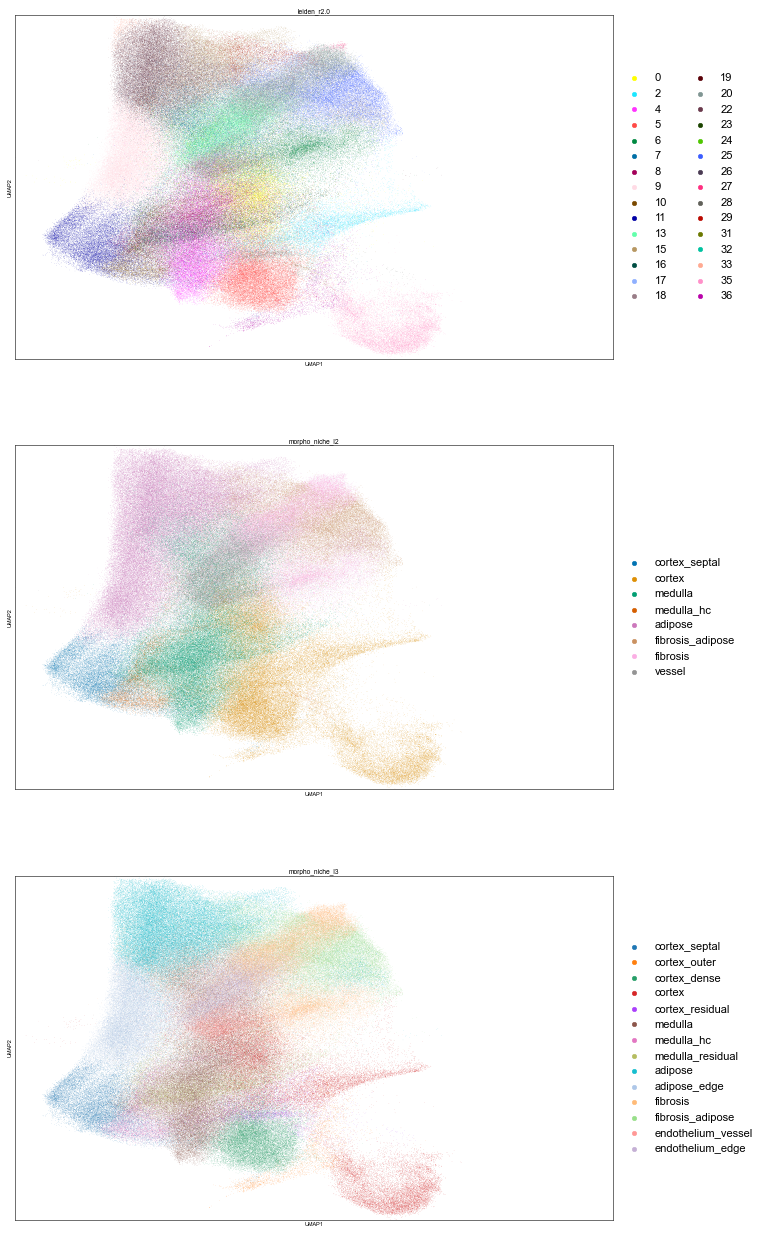

In [7]:
he_adata = he_adata[he_adata.obs['morpho_niche_keep']]

# Define categorical order for morpho_niche_l3 and morpho_niche_l2
he_adata.obs['morpho_niche_l3'] = pd.Categorical(he_adata.obs['morpho_niche_l3'], categories=['cortex_septal','cortex_outer','cortex_dense', 'cortex', 'cortex_residual',
                    'medulla', 'medulla_hc', 'medulla_residual', 
                    'adipose', 'adipose_edge',
                    'fibrosis', 'fibrosis_adipose',
                    'endothelium_vessel', 'endothelium_edge',])
he_adata.obs['morpho_niche_l2'] = pd.Categorical(he_adata.obs['morpho_niche_l2'], categories=['cortex_septal','cortex', 'medulla', 'medulla_hc', 'adipose', 'fibrosis_adipose', 'fibrosis', 'vessel',])

sc.pl.umap(he_adata, color = ['leiden_r2.0', 'morpho_niche_l2','morpho_niche_l3'], legend_fontsize = 10, ncols = 1, wspace=0.3)

In [37]:
xenium_samples = he_meta.loc[he_meta['has_xenium'] == True]['SampleID'].unique()
niche_col = 'morpho_niche_l3'
for sample in xenium_samples:
    orig_mpp = he_meta[he_meta['SampleID'] == sample]['resolution'].values[0]
    palette = dict(zip(he_adata.obs[niche_col].cat.categories, he_adata.uns[f'{niche_col}_colors']))

    export_niches_to_geojson(he_adata, sample, niche_col, orig_mpp, palette)

9981 patches written
17840 patches written
21565 patches written
3138 patches written
7434 patches written
14655 patches written
12045 patches written
16504 patches written


In [10]:
niche_labels['morpho_niche_l2'].unique()

array(['cortex', 'artifact', 'medulla', 'vessel', 'adipose', 'medulla_hc',
       'adipose_fibrosis', 'fibrosis', 'cortex_dense'], dtype=object)

In [ ]:
from plotting.utils import freq_by_donor, plot_grouped_boxplot, get_tint_palette
col_niche = 'morpho_niche_l2'
col_niche_levels = he_adata.obs[col_niche].cat.categories.tolist()
anno_df = he_adata.obs[['DonorID', 'SampleID', 'age_group', col_niche, 'morpho_niche_keep']].copy()
anno_df = anno_df.loc[anno_df['morpho_niche_keep']]
df = freq_by_donor(anno_df, sample_col = 'SampleID', donor_col = 'DonorID', summary_col=col_niche, add_meta = ['age_group'])

plot_grouped_boxplot(data = df, x = col_niche, y = 'mean_prop', hue = 'age_group', order = col_niche_levels, hue_order = ['infant', 'paed', 'adult'], 
                    palette = get_tint_palette(thyAgeing_colors['magenta'], min_tint = 0.3, n = 3), annotator_args = dict(line_offset = 1, text_offset = -3.5, line_offset_to_group = 0.03),
                     x_label = 'Niche', y_label = 'Frequency', legend_title = 'Age group', add_stats = True, format_percent = True, figsize = calc_figsize(height = 60, width = len(col_niche_levels)*5+20),
                     save_stats = f'{data_path}/morpho_niches/thyAgeing_{col_niche}_proportions_boxplot_')
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAgeing_{col_niche}_proportions_boxplot.pdf', bbox_inches='tight', dpi=300)

/tmp/ipykernel_629896/3987636145.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_counts, y='count', x='niche', palette=palette, order=df_counts['niche'], ax=ax)


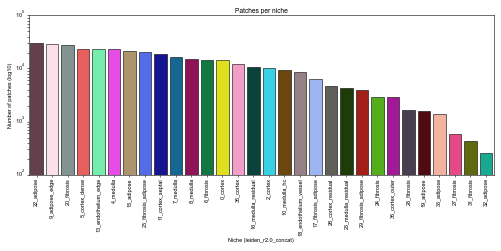

In [13]:
plot_df = he_adata.obs[['leiden_r2.0_concat']].value_counts()
df_counts = plot_df.reset_index()
df_counts.columns = ['niche', 'count']
df_counts['niche'] = df_counts['niche'].astype(str)
df_counts = df_counts.sort_values('count', ascending=False)

palette = dict(zip(he_adata.obs['leiden_r2.0_concat'].cat.categories, he_adata.uns['leiden_r2.0_colors']))

fig, ax = plt.subplots(figsize=calc_figsize(width=160, height=80))
sns.barplot(data=df_counts, y='count', x='niche', palette=palette, order=df_counts['niche'], ax=ax)
ax.set_yscale('log', base=10)
ax.set_xlabel('Niche (leiden_r2.0_concat)')
ax.set_ylabel('Number of patches (log10)')
plt.xticks(rotation=90, ha='center')
ax.set_title('Patches per niche')
plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/patches_per_cluster_barplot.png', bbox_inches='tight', dpi=300)
plt.show()

In [14]:
he_adata.obs[['has_xenium', 'DonorID', 'SampleID']].drop_duplicates().groupby(['has_xenium']).agg(n_donors=('DonorID', 'nunique'), n_samples=('SampleID', 'nunique'))

,n_donors,n_samples
has_xenium,,
False,14,24
True,8,8


### Extract exemplary patches per niche

In [7]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages


def default_image_path(sample, data_dir, mpp_tag="mpp025", part="part0"):
    """Matches preprocess_morpho.py output naming."""
    return Path(data_dir) / f"{sample}_processed" / f"{sample}_{part}_image_he_{mpp_tag}.npy"

def make_npy_reader(image_path_fn=None, data_dir=None, mpp_tag="mpp025"):
    """Read crops from the saved mpp025 .npy images (coords used as-is)."""
    if image_path_fn is None:
        image_path_fn = lambda s: default_image_path(s, data_dir, mpp_tag=mpp_tag)
    cache = {}
    def read(sample, row, coord_cols):
        p = Path(image_path_fn(sample))
        if p not in cache:
            cache[p] = np.load(p, mmap_mode="r") if p.exists() else None
            if cache[p] is None:
                print(f"[WARN] missing .npy for {sample}: {p}")
        img = cache[p]
        if img is None:
            return None
        H, W = img.shape[:2]
        x0c, y0c, x1c, y1c = coord_cols
        x0, x1 = max(0, int(round(row[x0c]))), min(W, int(round(row[x1c])))
        y0, y1 = max(0, int(round(row[y0c]))), min(H, int(round(row[y1c])))
        return np.asarray(img[y0:y1, x0:x1])
    return read


def _pick_with_cap(ordered_pos, ordered_samples, n, cap):
    """Take first n positions, but at most `cap` from any one sample (diversity)."""
    if cap is None:
        return list(ordered_pos[:n])
    counts, picked = {}, []
    for p, s in zip(ordered_pos, ordered_samples):
        if counts.get(s, 0) >= cap:
            continue
        picked.append(p); counts[s] = counts.get(s, 0) + 1
        if len(picked) >= n:
            return picked
    # backfill ignoring cap if the cap left us short
    for p in ordered_pos:
        if p not in picked:
            picked.append(p)
            if len(picked) >= n:
                break
    return picked

def extract_niche_exemplars_pdf(
    adata, niche_col, out_pdf, reader, *,
    sample_col="SampleID", coord_cols=("x0", "y0", "x1", "y1"),
    n_per_niche=16, ncols=4, selection="representative",
    embedding_key="X_uni", per_sample_cap=None, seed=0, dpi=150,
):
    obs = adata.obs
    rng = np.random.default_rng(seed)
    samples = obs[sample_col].to_numpy()
    have_emb = selection == "representative" and embedding_key in adata.obsm
    niches = ([c for c in obs[niche_col].cat.categories if (obs[niche_col] == c).any()]
              if hasattr(obs[niche_col], "cat")
              else sorted(obs[niche_col].dropna().unique()))

    with PdfPages(out_pdf) as pdf:
        for niche in niches:
            pos = np.where((obs[niche_col] == niche).to_numpy())[0]
            if len(pos) == 0:
                continue
            if have_emb:
                Xg = np.asarray(adata.obsm[embedding_key])[pos]
                order = pos[np.argsort(np.linalg.norm(Xg - Xg.mean(0, keepdims=True), axis=1))]
            else:
                order = rng.permutation(pos)
            chosen = _pick_with_cap(order, samples[order], n_per_niche, per_sample_cap)

            nrows = int(np.ceil(len(chosen) / ncols))
            fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.4, nrows * 2.6), dpi=dpi)
            axes = np.atleast_1d(axes).ravel()
            for ax in axes:
                ax.axis("off")
            for ax, p in zip(axes, chosen):
                row = obs.iloc[p]
                patch = reader(row[sample_col], row, coord_cols)     # <-- pluggable source
                if patch is None or patch.size == 0:
                    continue
                ax.imshow(patch)
                ax.set_title(f"{row[sample_col]}\n{obs.index[p]}", fontsize=5)
                ax.axis("off")
            fig.suptitle(f"{niche_col} = {niche}   (n={len(pos)}, showing {len(chosen)})", fontsize=11)
            fig.tight_layout(rect=[0, 0, 1, 0.96])
            pdf.savefig(fig); plt.close(fig)
    print(f"✅ Saved {out_pdf}")


In [12]:
reader = make_npy_reader(data_dir="/lustre/scratch126/cellgen/teichmann/lm25/data/thymus_he/thyAgeing_HnE")

niche_col = 'morpho_niche_l2'
extract_niche_exemplars_pdf(
    he_adata, niche_col,
    f"{plots_path}/morpho_niches2/discovery/thyAgeing_{niche_col}_niche_exemplars_random.pdf",
    reader, n_per_niche=36, ncols=6, per_sample_cap=5,selection="random",
)

2026-07-24 15:29:01 | [INFO] maxp pruned
2026-07-24 15:29:01 | [INFO] LTSH dropped
2026-07-24 15:29:01 | [INFO] cmap pruned
2026-07-24 15:29:01 | [INFO] kern pruned
2026-07-24 15:29:01 | [INFO] post pruned
2026-07-24 15:29:01 | [INFO] PCLT dropped
2026-07-24 15:29:01 | [INFO] JSTF dropped
2026-07-24 15:29:01 | [INFO] DSIG dropped
2026-07-24 15:29:01 | [INFO] GSUB pruned
2026-07-24 15:29:01 | [INFO] glyf pruned
2026-07-24 15:29:01 | [INFO] Added gid0 to subset
2026-07-24 15:29:01 | [INFO] Added first four glyphs to subset
2026-07-24 15:29:01 | [INFO] Closing glyph list over 'GSUB': 52 glyphs before
2026-07-24 15:29:01 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'E', 'F', 'H', 'P', 'S', 'T', 'U', 'Y', 'Z', 'a', 'b', 'c', 'comma', 'd', 'e', 'eight', 'equal', 'f', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'u', 'underscore', 'v', 'w', 'x

✅ Saved /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots//morpho_niches2/discovery/thyAgeing_morpho_niche_l2_niche_exemplars_random.pdf


In [4]:
he_adata

AnnData object with n_obs × n_vars = 415178 × 1536
    obs: 'sample', 'x0', 'y0', 'x1', 'y1', 'cx_img', 'cy_img', 'tile_size', 'stride', 'tissue_fraction', 'red_fraction', 'valid_tissue_fraction', 'saturation_fraction', 'dark_fraction', 'gray_std', 'grid_row', 'grid_col', 'component_id', 'component_size', 'component_height_tiles', 'component_width_tiles', 'mpp', 'tile_physical_size_um', 'stride_physical_um', 'part_name', 'source_image', 'original_file', 'data_type', 'part_batch', 'SampleID', 'DonorID', 'sex', 'age_group', 'tissue_embedding', 'has_xenium', 'source', 'leiden_r1.0', 'leiden_r0.5', 'leiden_r2.0', 'morpho_niche_l3', 'morpho_niche_l2', 'morpho_niche_l1', 'morpho_niche_keep', 'leiden_r2.0_concat'
    uns: 'DonorID_colors', 'age_group_colors', 'has_xenium_colors', 'leiden_r0.5', 'leiden_r0.5_colors', 'leiden_r1.0', 'leiden_r1.0_colors', 'leiden_r2.0', 'leiden_r2.0_colors', 'neighbors', 'pca', 'sex_colors', 'source_colors', 'tissue_embedding_colors', 'umap'
    obsm: 'X_pca', '

## Map Xenium cell types to H&E patches

In [ ]:
xenium_adata = ad.read_h5ad('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/xenium_proseg/xenium_aging_labels.h5ad')

# Add cell coordinates
xenium_adata_spatial = ad.read_h5ad('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/xenium_proseg/xenium_proseg_aging.h5ad', backed = 'r')
xenium_adata.obsm['spatial'] = xenium_adata_spatial.obsm['spatial']

xenium_cellanno = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_v1-v2_predict_2026-07-15.csv', index_col=0)[['proseg_barcode', 'taa_l2_comb', 'taa_l3_comb', 'niche_cellcharter3_v2_comb', 'niche_cellcharter6_comb']].set_index('proseg_barcode')
xenium_adata.obs[xenium_cellanno.columns] = xenium_cellanno.loc[xenium_adata.obs_names, :]

xenium_adata

/tmp/ipykernel_1164375/2563105578.py:7: DtypeWarning: Columns (35,36,37,38) have mixed types. Specify dtype option on import or set low_memory=False.
  xenium_cellanno = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_v1-v2_predict_2026-07-15.csv', index_col=0)[['proseg_barcode', 'taa_l2_comb', 'taa_l3_comb', 'niche_cellcharter3_v2_comb', 'niche_cellcharter6_comb']].set_index('proseg_barcode')


AnnData object with n_obs × n_vars = 3531679 × 5043
    obs: 'sample_ID', 'donor', 'chemistry_simple', 'cells_spatial', '_scvi_batch', '_scvi_labels', 'X_scVI_shortlist_v1_leiden_1', 'level_0_pred', 'level_0_prob', 'level_1_pred', 'level_1_prob', 'level_2_pred', 'level_2_prob', 'level_3_pred', 'level_3_prob', 'level_4_pred', 'level_4_prob', 'level_5_pred', 'level_5_prob', 'level_2v2_pred', 'level_2v2_prob', 'level_3v2_pred', 'level_3v2_prob', 'taa_l2_comb', 'taa_l3_comb', 'niche_cellcharter3_v2_comb', 'niche_cellcharter6_comb'
    uns: 'X_scVI_shortlist_v1_leiden_1', '_scvi_manager_uuid', '_scvi_uuid', 'cells_spatial_colors', 'log1p', 'neighbors', 'umap'
    obsm: 'X_scVI_shortlist_v1', 'X_umap', '_scvi_extra_categorical_covs', 'spatial'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [5]:
# Check for missing values in the 'taa_l3_comb' column of the xenium_adata observations
xenium_adata.obs['taa_l3_comb'].isna().sum()

np.int64(0)

In [6]:
# Map HnE coordinates to microns
mpp = 0.25  
patch_px = 224
patch_um = patch_px * mpp  

he_adata.obs[['x0_um', 'y0_um', 'x1_um', 'y1_um']] = np.int16(he_adata.obs[['x0', 'y0', 'x1', 'y1']] * mpp)
he_adata.obs[['patch_col', 'patch_row']] = (he_adata.obs[['x0', 'y0']] // patch_px).astype(int) 
he_adata.obs.head()

,sample,x0,y0,x1,y1,cx_img,cy_img,tile_size,stride,tissue_fraction,...,morpho_niche_l2,morpho_niche_l1,morpho_niche_keep,leiden_r2.0_concat,x0_um,y0_um,x1_um,y1_um,patch_col,patch_row
tile_id,,,,,,,,,,,,,,,,,,,,,
A70-THY-0-FFPE-1_tile_00000000,A70-THY-0-FFPE-1,26208,1792,26432,2016,26320.0,1904.0,224,224,0.242128,...,fibrosis_adipose,fibrosis_adipose,True,29_fibrosis_adipose,6552,448,6608,504,117,8
A70-THY-0-FFPE-1_tile_00000001,A70-THY-0-FFPE-1,26432,1792,26656,2016,26544.0,1904.0,224,224,0.549685,...,fibrosis_adipose,fibrosis_adipose,True,17_fibrosis_adipose,6608,448,6664,504,118,8
A70-THY-0-FFPE-1_tile_00000002,A70-THY-0-FFPE-1,26656,1792,26880,2016,26768.0,1904.0,224,224,0.416354,...,fibrosis,fibrosis,True,6_fibrosis,6664,448,6720,504,119,8
A70-THY-0-FFPE-1_tile_00000003,A70-THY-0-FFPE-1,26880,1792,27104,2016,26992.0,1904.0,224,224,0.915537,...,fibrosis,fibrosis,True,6_fibrosis,6720,448,6776,504,120,8
A70-THY-0-FFPE-1_tile_00000004,A70-THY-0-FFPE-1,27104,1792,27328,2016,27216.0,1904.0,224,224,0.570532,...,fibrosis_adipose,fibrosis_adipose,True,25_fibrosis_adipose,6776,448,6832,504,121,8


In [7]:
import numpy as np

alignment_dir = f'{data_path}/xenium/he_alignments'
PIXEL_SIZE    = 0.2125   # µm/px of the Xenium morphology image (matrix.csv domain)
HE_PIXEL_SIZE = 0.221    # µm/px of the H&E image
scale = HE_PIXEL_SIZE / mpp   # H&E native px -> target-mpp (0.25) px

def apply_affine(M, xy):
    """Apply a 3x3 affine to an (n,2) array of (x, y) points."""
    h = np.hstack([xy, np.ones((len(xy), 1))])
    return (h @ M.T)[:, :2]

xenium_coords_transformed = np.array([]).reshape(0, 2)  # Initialize empty array to hold transformed coordinates
xenium_obs_names = []
for donor in xenium_adata.obs['donor'].unique():
    _rotation_matrix = pd.read_csv(os.path.join(alignment_dir,f'{donor}_alignment_files', f'matrix.csv'), header=None).values

    # 1. cell centroids in microns, as (x, y)
    _xenium_coords = xenium_adata[xenium_adata.obs['donor'] == donor].obsm['spatial']#[:, [1, 0]]  # swap cols -> (x, y)
    # 2. microns -> Xenium pixels
    _xenium_coords_px = _xenium_coords / PIXEL_SIZE  # (x, y) in Xenium pixel space

    # 3. Xenium pixels -> H&E pixels (inverse, because the Explorer matrix maps H&E -> Xenium)
    Minv = np.linalg.inv(_rotation_matrix)
    xenium_coords_transformed = np.vstack([xenium_coords_transformed, apply_affine(Minv, _xenium_coords_px)])  # (x, y) in H&E pixel space

    # Save obs_names to add back into main anndata
    xenium_obs_names.extend(xenium_adata[xenium_adata.obs['donor'] == donor].obs_names)

# Concatenate and align xenium_coords_transformed to xenium_adata.obs_names order
xenium_coords_transformed = pd.DataFrame(xenium_coords_transformed, index=xenium_obs_names, columns=['x_he_px', 'y_he_px'])
xenium_coords_transformed = xenium_coords_transformed.reindex(xenium_adata.obs_names)

# Quick sanity checks
print(f"Reindexed shape: {xenium_coords_transformed.shape}")
print(f"Missing coords: {xenium_coords_transformed['x_he_px'].isna().sum()} / {xenium_coords_transformed.shape[0]}")

# Add transformed coordinates to xenium_adata.obsm
xenium_adata.obsm['spatial_transformed'] = xenium_coords_transformed.values * scale

# Add H&E sample IDs to xenium_adata.obs for downstream analysis
xenium_adata.obs['SampleID_he'] = xenium_adata.obs['donor'].astype(str) + '.ome'

# Fast vectorised assignment of cells to patches based on transformed coordinates
xenium_adata.obs["patch_col"] = (xenium_adata.obsm['spatial_transformed'][:, 0] // patch_px).astype(int)
xenium_adata.obs["patch_row"] = (xenium_adata.obsm['spatial_transformed'][:, 1] // patch_px).astype(int)

# Filter xenium_adata.obs outside tissue mask patches
he_adata_patching = he_adata.obs[['SampleID', 'patch_col', 'patch_row'] + niche_labels.columns.tolist()].reset_index(names='patchID').drop_duplicates().copy()
xenium_adata.obs.drop(columns=he_adata_patching.columns.difference(['SampleID_he', 'patch_col', 'patch_row']), errors='ignore', inplace=True)  # Drop columns if they exist to avoid conflicts
xenium_adata.obs = xenium_adata.obs.reset_index(names='index').merge(he_adata_patching, left_on = ['SampleID_he', 'patch_col', 'patch_row'], right_on = ['SampleID', 'patch_col', 'patch_row'], how = 'left', validate = "many_to_one").set_index('index')

xenium_adata.obs.head()

Reindexed shape: (3531679, 2)
Missing coords: 0 / 3531679


,sample_ID,donor,chemistry_simple,cells_spatial,_scvi_batch,_scvi_labels,X_scVI_shortlist_v1_leiden_1,level_0_pred,level_0_prob,level_1_pred,...,patch_col,patch_row,patchID,SampleID,leiden_r2.0,morpho_niche_l3,morpho_niche_l2,morpho_niche_l1,morpho_niche_keep,leiden_r2.0_concat
index,,,,,,,,,,,,,,,,,,,,,
xenium_A45-2,A45,A45,xenium,spatial,1,0,3,Epithelial,0.549949,TEC,...,140,26,A45.ome_tile_00002048,A45.ome,1,artifact,artifact,artifact,False,1_artifact
xenium_A45-5,A45,A45,xenium,spatial,1,0,3,Epithelial,0.599968,TEC,...,141,27,A45.ome_tile_00002171,A45.ome,22,adipose,adipose,adipose,True,22_adipose
xenium_A45-10,A45,A45,xenium,spatial,1,0,3,Stroma,0.500008,Fb,...,140,29,A45.ome_tile_00002428,A45.ome,13,endothelium_edge,vessel,vessel,True,13_endothelium_edge
xenium_A45-13,A45,A45,xenium,spatial,1,0,3,Stroma,0.450024,Fb,...,141,30,A45.ome_tile_00002563,A45.ome,12,tissue_edge,artifact,artifact,False,12_tissue_edge
xenium_A45-19,A45,A45,xenium,spatial,1,0,8,Stroma,0.950000,Fb,...,140,29,A45.ome_tile_00002428,A45.ome,13,endothelium_edge,vessel,vessel,True,13_endothelium_edge


In [8]:
# Filter xenium_adata to keep only cells that fall within tissue mask patches
xenium_adata = xenium_adata[xenium_adata.obs['leiden_r2.0'].notna()]  # Keep only cells that fall within tissue mask patches

In [ ]:
from matplotlib.colors import ListedColormap
from typing import Union

res = 2.0
leiden_col = 'leiden_r' + str(res)
xenium_adata.obs[leiden_col] = pd.Categorical(xenium_adata.obs[leiden_col], categories = sorted(xenium_adata.obs[leiden_col].unique(), key = lambda x: int(x)))
patch_n = xenium_adata.obs.groupby(leiden_col).size()

min_patches = 1000
valid_cat = patch_n.loc[patch_n >= min_patches].index.tolist()

xenium_adata.obs['spatial_cat'] = xenium_adata.obs[leiden_col].where(xenium_adata.obs[leiden_col].isin(valid_cat), other=pd.NA)
xenium_adata.obs['spatial_cat'] = xenium_adata.obs['spatial_cat'].cat.remove_unused_categories()
xenium_adata.obs['spatial_cat'] = pd.Categorical(xenium_adata.obs['spatial_cat'], categories = sorted(xenium_adata.obs['spatial_cat'].cat.categories, key = lambda x: int(x)))

# Use a single, global color mapping for the clustering
cats = he_adata.obs[leiden_col].cat.categories.tolist()
colors = he_adata.uns[leiden_col + '_colors']
colors = [plt.matplotlib.colors.rgb2hex(c) for c in colors]
palette = dict(zip(cats, colors))

# Manually define colors to obs column where Squidpy expects or creates them
xenium_adata.obs["spatial_cat_colors"] = xenium_adata.obs["spatial_cat"].map(palette)
#del xenium_adata.uns["spatial_cat_colors"] 


for lib in ['A45', 'U51', 'A70', 'U48', 'Z16', 'A72', 'Z17', 'A67']:
    
    sq.pl.spatial_scatter(
                xenium_adata,
                library_key='sample_ID',
                library_id=[lib],
                title=[lib],
                color = 'spatial_cat',
                #palette = ListedColormap(list(palette.values())),
                shape=None,
                size=0.1,
                img=None,
                figsize=calc_figsize(width = 200, height = 200),
                ncols=3,
                frameon=False,
                return_ax=True,
                dpi = 300,
                save = f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_leiden_m2_r{res}_{lib}_spatial.png',
            )
    plt.show()

In [ ]:
from matplotlib.colors import ListedColormap
from typing import Union

col_niche = 'morpho_niche_l3' 
xenium_adata.obs[col_niche] = pd.Categorical(xenium_adata.obs[col_niche], categories = he_adata.obs[col_niche].cat.categories.tolist())
xenium_adata.obs['spatial_cat'] = xenium_adata.obs[col_niche].copy()
xenium_adata.obs['spatial_cat'] = pd.Categorical(xenium_adata.obs['spatial_cat'], categories = he_adata.obs[col_niche].cat.categories.tolist())

# Use a single, global color mapping for the clustering
cats = he_adata.obs[col_niche].cat.categories.tolist()
colors = he_adata.uns[col_niche + '_colors']
colors = [plt.matplotlib.colors.rgb2hex(c) for c in colors]
palette = dict(zip(cats, colors))

# Manually define colors to obs column where Squidpy expects or creates them
xenium_adata.obs["spatial_cat_colors"] = xenium_adata.obs["spatial_cat"].map(palette)
#del xenium_adata.uns["spatial_cat_colors"] 


for lib in ['A45', 'U51', 'A70', 'U48', 'Z16', 'A72', 'Z17', 'A67']:
    
    sq.pl.spatial_scatter(
                xenium_adata,
                library_key='sample_ID',
                library_id=[lib],
                title=[lib],
                color = 'spatial_cat',
                #palette = ListedColormap(list(palette.values())),
                shape=None,
                size=0.1,
                img=None,
                figsize=calc_figsize(width = 200, height = 200),
                ncols=3,
                frameon=False,
                return_ax=True,
                dpi = 300,
                save = f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_{col_niche}_{lib}_spatial.png',
            )
    plt.show()

In [9]:
# Save xenium_adata.obs with relevant columns to CSV for downstream analysis
xenium_adata.obs[['SampleID_he', 'patch_col', 'patch_row', 'patchID'] + niche_labels.columns.tolist()].to_csv(f'{data_path}/xenium/thyAging_xenium_morpho_niches.csv')

### Cell type enrichment in morphological niches

In [10]:
# Remove cells mapping to artifacts
xenium_adata = xenium_adata[xenium_adata.obs['morpho_niche_keep'] == True]

In [24]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

def cluster_enrichment(obs, leiden_col, anno_col, donor_col='DonorID', pseudocount=0.1):
    """
    Per-donor log2 observed/expected enrichment of each cell type in each cluster,
    aggregated across donors with a one-sample t-test (H0: log2 O/E = 0).
    O/E normalises out cluster size AND global cell-type abundance, so it is not
    dominated by abundant populations (e.g. DP thymocytes).
    """
    recs = []
    for donor, g in obs.groupby(donor_col, observed=True):
        ct = pd.crosstab(g[leiden_col], g[anno_col])
        N   = ct.values.sum()
        row = ct.sum(1).values[:, None]     # cells per cluster
        col = ct.sum(0).values[None, :]     # cells per cell type
        expected = row @ col / N
        log2oe = np.log2((ct.values + pseudocount) / (expected + pseudocount))
        tmp = pd.DataFrame(log2oe, index=ct.index, columns=ct.columns)
        tmp = tmp.reset_index().melt(id_vars=leiden_col, var_name=anno_col,
                                     value_name='log2oe')
        tmp[donor_col] = donor
        recs.append(tmp)
    long = pd.concat(recs, ignore_index=True)

    def agg(s):
        s = s.dropna()
        t, p = (stats.ttest_1samp(s, 0.0) if len(s) > 1 and s.std() > 0
                else (np.nan, np.nan))
        return pd.Series({'mean_log2oe': s.mean(), 'std_log2oe': s.std(ddof=1),
                          'n_donors': len(s), 't': t, 'pval': p})

    summary = (long.groupby([leiden_col, anno_col], observed=True)['log2oe']
                   .apply(agg).unstack().reset_index())
    m = summary['pval'].notna()
    summary.loc[m, 'padj'] = multipletests(summary.loc[m, 'pval'], method='fdr_bh')[1]
    return summary, long


In [ ]:
from plotting.utils import create_diverging_palette

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l3_comb'
niche_anno_col = 'leiden_r2.0_concat'
patch_summary = xenium_adata.obs[['donor','patchID', cell_anno_col, niche_anno_col]].copy()
summary, long = cluster_enrichment(patch_summary, niche_anno_col, cell_anno_col, donor_col='donor')

plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

# Order axes if categorical
if hasattr(summary[niche_anno_col], 'cat'):
    plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories)
if hasattr(summary[cell_anno_col], 'cat'):
    plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
    
#plot_df = plot_df.loc[~plot_df.index.str.contains('artifact')]
plot_df.fillna(0, inplace=True)

cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'], s = 90, l = 60, as_cmap = True)

vmax = 3
fig, ax = plt.subplots(figsize=calc_figsize(width=220, height=plot_df.shape[0]*5))
g = sns.clustermap(
    plot_df,
    cmap=cmap,
    center=0,
    vmin=-vmax,
    vmax=vmax,
    figsize=calc_figsize(width=220, height=plot_df.shape[0]*5),
    cbar_kws={'label': 'mean_log2oe'},
    row_cluster=True,
    col_cluster=True,
    #dendrogram_ratio=(0.06, 0.06),   # reduce dendrogram -> heatmap gap
    cbar_pos=(0.02, 0.75, 0.03, 0.18),
    tree_kws={'linewidth': 0.5},
    xticklabels=True,
    yticklabels=True,
)
ax = g.ax_heatmap
plt.setp(ax.get_xticklabels(), fontsize=8)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8)
ax.set_xlabel(cell_anno_col)
ax.set_ylabel(niche_anno_col)
#plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_log2oe_clustermap.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
from plotting.utils import create_diverging_palette

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l3_comb'
niche_anno_col = 'morpho_niche_l3'
patch_summary = xenium_adata.obs[['donor','patchID', cell_anno_col, niche_anno_col]].copy()
summary, long = cluster_enrichment(patch_summary, niche_anno_col, cell_anno_col, donor_col='donor')

plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

# Order axes if categorical
if hasattr(summary[niche_anno_col], 'cat'):
    plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories)
if hasattr(summary[cell_anno_col], 'cat'):
    plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
    
#plot_df = plot_df.loc[~plot_df.index.str.contains('artifact')]
plot_df.fillna(0, inplace=True)

cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'], s = 90, l = 60, as_cmap = True)

vmax = 3
fig, ax = plt.subplots(figsize=calc_figsize(width=220, height=plot_df.shape[0]*5))
g = sns.clustermap(
    plot_df,
    cmap=cmap,
    center=0,
    vmin=-vmax,
    vmax=vmax,
    figsize=calc_figsize(width=220, height=plot_df.shape[0]*5),
    cbar_kws={'label': 'mean_log2oe'},
    row_cluster=True,
    col_cluster=True,
    #dendrogram_ratio=(0.06, 0.06),   # reduce dendrogram -> heatmap gap
    cbar_pos=(0.02, 0.75, 0.03, 0.18),
    tree_kws={'linewidth': 0.5},
    xticklabels=True,
    yticklabels=True,
)
ax = g.ax_heatmap
plt.setp(ax.get_xticklabels(), fontsize=8)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8)
ax.set_xlabel(cell_anno_col)
ax.set_ylabel(niche_anno_col)
#plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_log2oe_clustermap.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
import seaborn as sns
mat = xenium_adata.obs.groupby(['leiden_r2.0_concat', 'taa_l3_comb'], observed=True).size().unstack(fill_value=0)
# z-score each cell type (column) across clusters
z = (mat - mat.mean(0)) / mat.std(0)

cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'], s = 90, l = 60, as_cmap = True)

vmax = 3
fig, ax = plt.subplots(figsize=calc_figsize(width=220, height=plot_df.shape[0]*5))
g = sns.clustermap(
    z,
    cmap=cmap,
    center=0,
    vmin=-vmax,
    vmax=vmax,
    figsize=calc_figsize(width=220, height=plot_df.shape[0]*5),
    cbar_kws={'label': 'mean_log2oe'},
    row_cluster=True,
    col_cluster=True,
    #dendrogram_ratio=(0.06, 0.06),   # reduce dendrogram -> heatmap gap
    cbar_pos=(0.02, 0.75, 0.03, 0.18),
    tree_kws={'linewidth': 0.5},
    xticklabels=True,
    yticklabels=True,
)
ax = g.ax_heatmap
plt.setp(ax.get_xticklabels(), fontsize=8)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8)
ax.set_xlabel(cell_anno_col)
ax.set_ylabel(niche_anno_col)
#plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_zscore_clustermap.pdf', bbox_inches='tight', dpi=300)
plt.show()


In [ ]:
av_cells_per_patch_niche = xenium_adata.obs.groupby([niche_anno_col, 'patchID'], observed=True).size()
av_cells_per_patch_niche = av_cells_per_patch_niche.groupby(niche_anno_col, observed=True).mean().to_frame('av_cells_per_patch').reset_index()

df = av_cells_per_patch_niche.copy()
df[niche_anno_col] = df[niche_anno_col].astype(str)
palette = dict(zip(xenium_adata.obs[niche_anno_col].cat.categories, he_adata.uns['leiden_r2.0_colors']))

fig, ax = plt.subplots(figsize=calc_figsize(width=160, height=80))
sns.barplot(data=df, y='av_cells_per_patch', x=niche_anno_col, palette=palette, order=df[niche_anno_col], ax=ax)
ax.set_xlabel(niche_anno_col)
ax.set_ylabel('Average number of cells per patch (log10)')
plt.xticks(rotation=90, ha='center')
ax.set_title('Average cells per patch by niche')
plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_{niche_anno_col}_cell_density_barplot.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
with plt.rc_context({'figure.figsize' : calc_figsize(width = 150, height = 200)}):
    sc.pl.umap(he_adata, color=['morpho_niche_l3', 'morpho_niche_l2'], legend_fontsize = 10, ncols = 1, wspace=0.3, return_fig = True, show = False)
    plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAgeing_bbknn_umap_morpho_niche_l3.png', bbox_inches='tight', dpi = 300)
    plt.show()

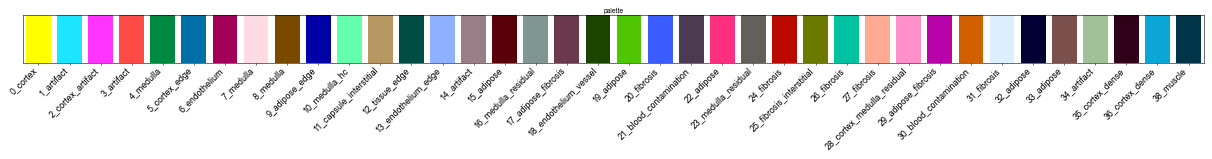

In [61]:
# Plot palette swatches
palette2 = dict(zip(xenium_adata.obs[niche_anno_col].cat.categories, he_adata.uns['leiden_r2.0_colors']))
colors = list(palette2.items())
n = len(colors)
fig, ax = plt.subplots(figsize=(n * 0.4, 2))
ax.bar(range(n), [1]*n, color=[c for _, c in colors], edgecolor='none')
ax.set_xticks(range(n))
ax.set_xticklabels([k for k, _ in colors], rotation=45, ha='right', fontsize=8)
ax.set_yticks([])
ax.set_xlim(-0.5, n-0.5)
ax.set_title('palette')
plt.tight_layout()
plt.show()

niche 10 maybe mcTEC-rich

In [ ]:
import seaborn as sns

# Percentual niche composition per DonorID for leiden_m2_r{res}
niche_anno_col = 'leiden_r2.0_concat'
ct = pd.crosstab(xenium_adata.obs['donor'], xenium_adata.obs[niche_anno_col], dropna=False)
pct = ct.div(ct.sum(axis=1), axis=0) * 100

# Consistent numeric column order
cols = sorted(pct.columns.astype(str), key=lambda x: int(x) if x.isdigit() else x)
pct = pct.reindex(columns=cols, fill_value=0)

# Order rows by donor age
#donor_order = xenium_adata.obs.drop_duplicates('donor').set_index('donor').loc[pct.index].sort_values('age_months')['age_months'].index
#pct = pct.reindex(index=donor_order)

palette = dict(zip(xenium_adata.obs[niche_anno_col].cat.categories, he_adata.uns['leiden_r2.0_colors']))

# Exclude small clusters
#pct = pct.loc[:, valid_cat]
fig, ax = plt.subplots(figsize=calc_figsize(width=120, height=120))

x = np.arange(len(pct.index))
bottom = np.zeros(len(pct.index), dtype=float)

for c in pct.columns:
    values = pct[c].to_numpy()
    ax.bar(
        x,
        values,
        bottom=bottom,
        color=palette.get(str(c), "#cccccc"),
        width=0.8,
        label=str(c),
        edgecolor="none",
    )
    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(pct.index)
ax.set_xlabel("DonorID")
ax.set_ylabel("Percent")
ax.set_title(f"Percentual composition of {niche_anno_col} per DonorID")
ax.legend(title=f"{niche_anno_col}", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine(ax=ax, trim=True, offset=(0, 5))

plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_mf2_{niche_anno_col}_niche_composition_per_DonorID.png', dpi=300)
plt.show()

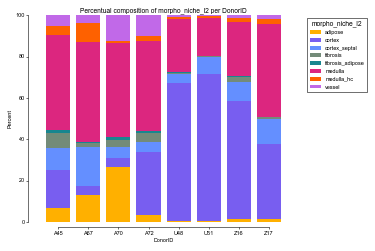

In [38]:
import seaborn as sns

# Pick 8 most distinct colors from thyAgeing_colors
color_names = list(thyAgeing_colors.keys())
selected_colors = color_names[:8]  # Take first 8 colors
palette_8colors = {name: thyAgeing_colors[name] for name in selected_colors}

palette_8colors

# Percentual niche composition per DonorID for leiden_m2_r{res}
niche_anno_col = 'morpho_niche_l2'
ct = pd.crosstab(xenium_adata.obs['donor'], xenium_adata.obs[niche_anno_col], dropna=False)
pct = ct.div(ct.sum(axis=1), axis=0) * 100

# Consistent numeric column order
cols = sorted(pct.columns.astype(str), key=lambda x: int(x) if x.isdigit() else x)
pct = pct.reindex(columns=cols, fill_value=0)

# Order rows by donor age
#donor_order = xenium_adata.obs.drop_duplicates('donor').set_index('donor').loc[pct.index].sort_values('age_months')['age_months'].index
#pct = pct.reindex(index=donor_order)

col_niche_levels = xenium_adata.obs[niche_anno_col].cat.categories.tolist()
colors = [list(thyAgeing_colors.values())[i] for i, niche in enumerate(col_niche_levels)]
palette = dict(zip(col_niche_levels, colors))

# Exclude small clusters
#pct = pct.loc[:, valid_cat]
fig, ax = plt.subplots(figsize=calc_figsize(width=120, height=80))

x = np.arange(len(pct.index))
bottom = np.zeros(len(pct.index), dtype=float)

for c in pct.columns:
    values = pct[c].to_numpy()
    ax.bar(
        x,
        values,
        bottom=bottom,
        color=palette.get(str(c), "#cccccc"),
        width=0.8,
        label=str(c),
        edgecolor="none",
    )
    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(pct.index)
ax.set_xlabel("DonorID")
ax.set_ylabel("Percent")
ax.set_title(f"Percentual composition of {niche_anno_col} per DonorID")
ax.legend(title=f"{niche_anno_col}", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine(ax=ax, trim=True, offset=(0, 5))

plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_mf2_{niche_anno_col}_niche_composition_per_DonorID.png', dpi=300)
plt.show()

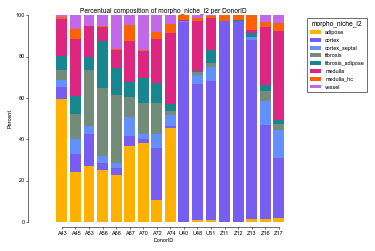

In [40]:
import seaborn as sns

# Pick 8 most distinct colors from thyAgeing_colors
color_names = list(thyAgeing_colors.keys())
selected_colors = color_names[:8]  # Take first 8 colors
palette_8colors = {name: thyAgeing_colors[name] for name in selected_colors}

palette_8colors

# Percentual niche composition per DonorID for leiden_m2_r{res}
niche_anno_col = 'morpho_niche_l2'
ct = pd.crosstab(he_adata.obs['DonorID'], he_adata.obs[niche_anno_col], dropna=False)
pct = ct.div(ct.sum(axis=1), axis=0) * 100

# Consistent numeric column order
cols = sorted(pct.columns.astype(str), key=lambda x: int(x) if x.isdigit() else x)
pct = pct.reindex(columns=cols, fill_value=0)

# Order rows by donor age
#donor_order = xenium_adata.obs.drop_duplicates('donor').set_index('donor').loc[pct.index].sort_values('age_months')['age_months'].index
#pct = pct.reindex(index=donor_order)

col_niche_levels = xenium_adata.obs[niche_anno_col].cat.categories.tolist()
colors = [list(thyAgeing_colors.values())[i] for i, niche in enumerate(col_niche_levels)]
palette = dict(zip(col_niche_levels, colors))

# Exclude small clusters
#pct = pct.loc[:, valid_cat]
fig, ax = plt.subplots(figsize=calc_figsize(width=120, height=80))

x = np.arange(len(pct.index))
bottom = np.zeros(len(pct.index), dtype=float)

for c in pct.columns:
    values = pct[c].to_numpy()
    ax.bar(
        x,
        values,
        bottom=bottom,
        color=palette.get(str(c), "#cccccc"),
        width=0.8,
        label=str(c),
        edgecolor="none",
    )
    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(pct.index)
ax.set_xlabel("DonorID")
ax.set_ylabel("Percent")
ax.set_title(f"Percentual composition of {niche_anno_col} per DonorID")
ax.legend(title=f"{niche_anno_col}", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine(ax=ax, trim=True, offset=(0, 5))

plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_mf2_{niche_anno_col}_niche_composition_per_DonorID_area.png', dpi=300)
plt.show()

### Comparison with CellCharter niches

In [11]:
xenium_morpho = pd.read_csv(f'{data_path}/xenium/thyAging_xenium_morpho_niches.csv', index_col=0)
xenium_morpho = xenium_morpho.reindex(xenium_adata.obs_names)
xenium_adata.obs[xenium_morpho.columns] = xenium_morpho.loc[xenium_adata.obs_names, :]

xenium_adata = xenium_adata[xenium_adata.obs['morpho_niche_keep'] == True]

In [11]:
xenium_cellcharter = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_adata_infant_paed_adult_CellCharter_v3.2_clusters.csv', index_col = 0)[['cluster_cellcharter17_v3.2']]
xenium_cellcharter = xenium_cellcharter.reindex(xenium_adata.obs_names)
xenium_adata.obs[xenium_cellcharter.columns] = xenium_cellcharter.loc[xenium_adata.obs_names, :]

/tmp/ipykernel_1164375/3892660692.py:1: DtypeWarning: Columns (35,36,37,38) have mixed types. Specify dtype option on import or set low_memory=False.
  xenium_cellcharter = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_adata_infant_paed_adult_CellCharter_v3.2_clusters.csv', index_col = 0)[['cluster_cellcharter17_v3.2']]


In [14]:
from matplotlib.backends.backend_pdf import PdfPages

out_pdf = f'{plots_path}/morpho_niches2/discovery/thyAgeing_morphoNiches_cellcharter_confusion_matrices.pdf'
os.makedirs(os.path.dirname(out_pdf), exist_ok=True)

with PdfPages(out_pdf) as pdf:
    for cellcharter_col in ['cluster_cellcharter17_v3.2']:
        # morpho_niche_l3 vs cellcharter_col
        anno_df = xenium_adata.obs[['morpho_niche_l3', cellcharter_col]].copy()
        cm = pd.crosstab(anno_df['morpho_niche_l3'], anno_df[cellcharter_col])
        cm = cm.div(cm.sum(axis=0), axis=1)
        col_min = cm.min(axis=0)
        col_max = cm.max(axis=0)
        denom = (col_max - col_min).replace(0, 1)
        cm_scaled = (cm - col_min) / denom
        fig = plt.figure(figsize=calc_figsize(width=cm.shape[1] * 4 + 20, height=max(80, cm.shape[0] * 4)))
        sns.heatmap(cm_scaled, cmap='viridis', annot=False, linewidths=0.5, linecolor='white', cbar_kws={'label': 'min-max scaled'})
        plt.xlabel(f'{cellcharter_col}')
        plt.ylabel('morpho_niche_l3')
        plt.title(f'Confusion matrix (min-max scaled per column): morpho_niche_l3 vs {cellcharter_col}')
        plt.tight_layout()
        pdf.savefig(fig); plt.close(fig)

        # leiden_r2.0_concat vs cellcharter_col
        anno_df = xenium_adata.obs[['leiden_r2.0_concat', cellcharter_col]].copy()
        cm = pd.crosstab(anno_df['leiden_r2.0_concat'], anno_df[cellcharter_col])
        cm = cm.div(cm.sum(axis=0), axis=1)
        col_min = cm.min(axis=0)
        col_max = cm.max(axis=0)
        denom = (col_max - col_min).replace(0, 1)
        cm_scaled = (cm - col_min) / denom
        fig = plt.figure(figsize=calc_figsize(width=cm.shape[1] * 4 + 20, height=max(80, cm.shape[0] * 4)))
        sns.heatmap(cm_scaled, cmap='viridis', annot=False, linewidths=0.5, linecolor='white', cbar_kws={'label': 'min-max scaled'})
        plt.xlabel(f'{cellcharter_col}')
        plt.ylabel('leiden_r2.0_concat')
        plt.title(f'Confusion matrix (min-max scaled per column): leiden_r2.0_concat vs {cellcharter_col}')
        plt.tight_layout()
        pdf.savefig(fig); plt.close(fig)

2026-07-23 16:25:12 | [INFO] maxp pruned
2026-07-23 16:25:12 | [INFO] LTSH dropped
2026-07-23 16:25:12 | [INFO] cmap pruned
2026-07-23 16:25:12 | [INFO] kern pruned
2026-07-23 16:25:12 | [INFO] post pruned
2026-07-23 16:25:12 | [INFO] PCLT dropped
2026-07-23 16:25:12 | [INFO] JSTF dropped
2026-07-23 16:25:12 | [INFO] DSIG dropped
2026-07-23 16:25:12 | [INFO] GSUB pruned
2026-07-23 16:25:12 | [INFO] glyf pruned
2026-07-23 16:25:12 | [INFO] Added gid0 to subset
2026-07-23 16:25:12 | [INFO] Added first four glyphs to subset
2026-07-23 16:25:12 | [INFO] Closing glyph list over 'GSUB': 41 glyphs before
2026-07-23 16:25:12 | [INFO] Glyph names: ['.notdef', '.null', 'C', 'a', 'b', 'c', 'colon', 'd', 'e', 'eight', 'f', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'u', 'underscore', 'v', 'x', 'zero']
2026-07-23 16:25:12 | [INFO] Glyph IDs:   [0, 1,

In [13]:
anno_df = xenium_adata.obs[['patchID', 'cluster_cellcharter17_v3.2', 'morpho_niche_l3', 'leiden_r2.0_concat', 'donor']].copy()
patch_mode = (
    anno_df.dropna(subset=['cluster_cellcharter17_v3.2'])
    .groupby('patchID', observed=True)['cluster_cellcharter17_v3.2']
    .agg(lambda s: s.value_counts().idxmax())
    .reset_index()
    .rename(columns={'cluster_cellcharter17_v3.2': 'cluster_cellcharter17_v3.2_mode'})
)

# # merge back to patch table and save
# he_adata_patching = he_adata_patching.merge(patch_mode, on='patchID', how='left')
# #patch_mode.to_csv(f'{data_path}/xenium/patch_cluster_cellcharter17_v3.2_mode.csv', index=False)
# he_adata_patching
patch_mode = patch_mode.merge(anno_df[['patchID', 'morpho_niche_l3', 'leiden_r2.0_concat']].drop_duplicates(), on='patchID', how='left')
patch_mode

,patchID,cluster_cellcharter17_v3.2_mode,morpho_niche_l3,leiden_r2.0_concat
0,A67.ome_tile_00000027,11.0,medulla,7_medulla
1,A67.ome_tile_00000062,11.0,fibrosis,20_fibrosis
2,A67.ome_tile_00000065,10.0,adipose,22_adipose
3,A67.ome_tile_00000067,11.0,fibrosis,6_fibrosis
4,A67.ome_tile_00000068,11.0,fibrosis,20_fibrosis
...,...,...,...,...
71748,Z17.ome_tile_00007594,1.0,cortex_septal,11_cortex_septal
71749,Z17.ome_tile_00007595,1.0,cortex_septal,11_cortex_septal
71750,Z17.ome_tile_00007596,1.0,cortex_septal,11_cortex_septal
71751,Z17.ome_tile_00007597,1.0,cortex_septal,11_cortex_septal


<Axes: xlabel='morpho_niche_l3', ylabel='cluster_cellcharter17_v3.2_mode'>

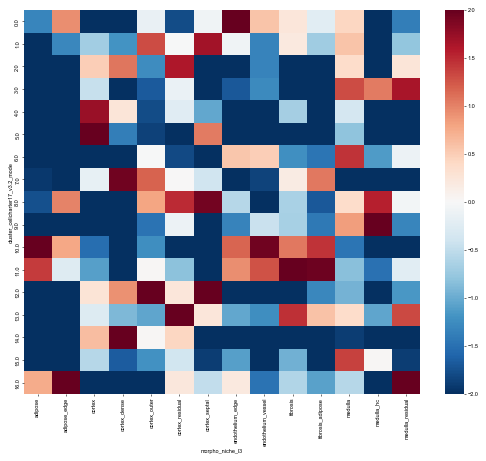

In [26]:
ct = pd.crosstab(patch_mode['cluster_cellcharter17_v3.2_mode'], patch_mode['morpho_niche_l3'])
N, row, col = ct.values.sum(), ct.sum(1).values[:,None], ct.sum(0).values[None,:]
oe = np.log2((ct.values + 0.5) / (row @ col / N + 0.5))
oe = pd.DataFrame(oe, index=ct.index, columns=ct.columns)
sns.heatmap(oe, cmap='RdBu_r', center=0, vmin=-2, vmax=2)


In [18]:
# Check whether the patches assigned to a given CellCharter cluster are recurred across donors, or private to a single donor
from sklearn.neighbors import NearestNeighbors
target_patches = patch_mode.loc[patch_mode['cluster_cellcharter17_v3.2_mode'] == 8.0, 'patchID'].unique()
X = he_adata.obsm['X_pca_coral']                      # H&E FM embedding, all 30 slides
is_target = he_adata.obs_names.isin(target_patches)
centroid = X[is_target].mean(0, keepdims=True)

nn = NearestNeighbors(n_neighbors=500).fit(X)
idx = nn.kneighbors(centroid, return_distance=False)[0]
hits = he_adata.obs.iloc[idx]
print(hits['DonorID'].value_counts())           # recurs across donors, or private?
print(hits['SampleID'].value_counts())   

DonorID
A72    134
A67     99
U48     85
Z17     80
A45     59
U51     15
Z16     14
A74      6
A70      6
A66      1
A56      1
A43      0
A53      0
Z11      0
U40      0
Z13      0
Z12      0
Name: count, dtype: int64
SampleID
A72.ome                              106
U48.ome                               85
Z17.ome                               80
A67.ome                               51
A67-THY-0-FFPE-1                      48
A45.ome                               46
U51.ome                               15
Z16.ome                               14
A72-THY-0-FFPE-3                      13
A45-THY-0-FFPE-1                      13
A72-THY-0-FFPE-1                       9
A74-THY-0-FFPE-3                       4
A72-THY-0-FFPE-2                       4
A70-THY-0-FFPE-1                       3
A70-THY-0-FFPE-2                       2
A74-THY-0-FFPE-2                       2
A72-THY-0-FFPE-4                       2
A66-THY-0-FFPE-1                       1
A56-THY-0-FF-1                  

In [16]:
# Check whether the patches assigned to a given CellCharter cluster are recurred across donors, or private to a single donor
from sklearn.neighbors import NearestNeighbors
target_patches = patch_mode.loc[patch_mode['cluster_cellcharter17_v3.2_mode'] == 16.0, 'patchID'].unique()
X = he_adata.obsm['X_pca_coral']                      # H&E FM embedding, all 30 slides
is_target = he_adata.obs_names.isin(target_patches)
centroid = X[is_target].mean(0, keepdims=True)

nn = NearestNeighbors(n_neighbors=500).fit(X)
idx = nn.kneighbors(centroid, return_distance=False)[0]
hits = he_adata.obs.iloc[idx]
print(hits['DonorID'].value_counts())           # recurs across donors, or private?

DonorID
A72    261
Z17     84
U48     77
A45     45
Z16     12
A67      7
U51      7
A70      7
A43      0
A74      0
A53      0
A56      0
A66      0
Z11      0
U40      0
Z13      0
Z12      0
Name: count, dtype: int64


In [36]:
TARGET = 8.0
comp = pd.crosstab(anno_df['patchID'], anno_df['cluster_cellcharter17_v3.2'], normalize ='index')

print("patches where TARGET is majority:",
      (comp.idxmax(1) == TARGET).sum(), "/", len(comp))
print(comp[TARGET].describe())     # how high does the target fraction get at all?

patches where TARGET is majority: 3299 / 71753
count    71753.000000
mean         0.044333
std          0.184685
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: 8.0, dtype: float64


In [40]:
he_adata

AnnData object with n_obs × n_vars = 415178 × 1536
    obs: 'sample', 'x0', 'y0', 'x1', 'y1', 'cx_img', 'cy_img', 'tile_size', 'stride', 'tissue_fraction', 'red_fraction', 'valid_tissue_fraction', 'saturation_fraction', 'dark_fraction', 'gray_std', 'grid_row', 'grid_col', 'component_id', 'component_size', 'component_height_tiles', 'component_width_tiles', 'mpp', 'tile_physical_size_um', 'stride_physical_um', 'part_name', 'source_image', 'original_file', 'data_type', 'part_batch', 'SampleID', 'DonorID', 'sex', 'age_group', 'tissue_embedding', 'has_xenium', 'source', 'leiden_r1.0', 'leiden_r0.5', 'leiden_r2.0', 'morpho_niche_l3', 'morpho_niche_l2', 'morpho_niche_l1', 'morpho_niche_keep', 'leiden_r2.0_concat'
    uns: 'DonorID_colors', 'age_group_colors', 'has_xenium_colors', 'leiden_r0.5', 'leiden_r0.5_colors', 'leiden_r1.0', 'leiden_r1.0_colors', 'leiden_r2.0', 'leiden_r2.0_colors', 'neighbors', 'pca', 'sex_colors', 'source_colors', 'tissue_embedding_colors', 'umap'
    obsm: 'X_pca', '

In [41]:
TH = 0.5                                   # or sweep 0.3–0.7
target_patches = comp.index[comp[TARGET] >= TH]
patch_he_niche = he_adata.obs[['SampleID', 'patch_col', 'patch_row', 'DonorID', 'morpho_niche_l3']].copy()
patch_he_niche['patchID'] = patch_he_niche['SampleID'].astype(str) + '_' + patch_he_niche['patch_col'].astype(str) + '_' + patch_he_niche['patch_row'].astype(str)
patch_he_niche = patch_he_niche.set_index('patchID', drop=False)
sub = patch_he_niche.loc[target_patches]   # patchID -> he_niche (+ DonorID)

# 1. Distribution over H&E niches
print(sub['he_niche'].value_counts(normalize=True).round(3))

# 2. Enrichment vs background (are they over-represented in any H&E niche?)
obs = sub['he_niche'].value_counts()
bg  = patch_he_niche['he_niche'].value_counts()
oe  = np.log2((obs / obs.sum()) / (bg / bg.sum())).sort_values()
print(oe)

# 3. CRITICAL with n=5: how many donors carry these patches?
print(sub.groupby('DonorID').size())


KeyError: "['patch_col', 'patch_row'] not in index"

In [25]:
patch_mode = patch_mode.dropna(subset=['cluster_cellcharter17_v3.2_mode']).copy()

from matplotlib.backends.backend_pdf import PdfPages

out_pdf = f'{plots_path}/morpho_niches2/discovery/thyAgeing_morphoNiches_cellcharter_confusion_matrices_area.pdf'
os.makedirs(os.path.dirname(out_pdf), exist_ok=True)

with PdfPages(out_pdf) as pdf:
    for cellcharter_col in ['cluster_cellcharter17_v3.2_mode']:
        # morpho_niche_l3 vs cellcharter_col (column scaled)
        cm = pd.crosstab(patch_mode['morpho_niche_l3'], patch_mode[cellcharter_col])
        cm = cm.div(cm.sum(axis=0), axis=1)
        col_min = cm.min(axis=0)
        col_max = cm.max(axis=0)
        denom = (col_max - col_min).replace(0, 1)
        cm_scaled = (cm - col_min) / denom
        fig = plt.figure(figsize=calc_figsize(width=cm.shape[1] * 4 + 20, height=max(80, cm.shape[0] * 4)))
        sns.heatmap(cm_scaled, cmap='viridis', annot=False, linewidths=0.5, linecolor='white', cbar_kws={'label': 'min-max scaled (per column)'})
        plt.xlabel(f'{cellcharter_col}')
        plt.ylabel('morpho_niche_l3')
        plt.title(f'Confusion matrix (min-max scaled per column): morpho_niche_l3 vs {cellcharter_col}')
        plt.tight_layout()
        pdf.savefig(fig); plt.close(fig)

        # leiden_r2.0_concat vs cellcharter_col (column scaled)
        cm = pd.crosstab(patch_mode['leiden_r2.0_concat'], patch_mode[cellcharter_col])
        cm = cm.div(cm.sum(axis=0), axis=1)
        col_min = cm.min(axis=0)
        col_max = cm.max(axis=0)
        denom = (col_max - col_min).replace(0, 1)
        cm_scaled = (cm - col_min) / denom
        fig = plt.figure(figsize=calc_figsize(width=cm.shape[1] * 4 + 20, height=max(80, cm.shape[0] * 4)))
        sns.heatmap(cm_scaled, cmap='viridis', annot=False, linewidths=0.5, linecolor='white', cbar_kws={'label': 'min-max scaled (per column)'})
        plt.xlabel(f'{cellcharter_col}')
        plt.ylabel('leiden_r2.0_concat')
        plt.title(f'Confusion matrix (min-max scaled per column): leiden_r2.0_concat vs {cellcharter_col}')
        plt.tight_layout()
        pdf.savefig(fig); plt.close(fig)

        # morpho_niche_l3 vs cellcharter_col (row scaled)
        cm = pd.crosstab(patch_mode['morpho_niche_l3'], patch_mode[cellcharter_col])
        cm = cm.div(cm.sum(axis=0), axis=1)
        row_min = cm.min(axis=1)
        row_max = cm.max(axis=1)
        denom_row = (row_max - row_min).replace(0, 1)
        cm_row_scaled = cm.sub(row_min, axis=0).div(denom_row, axis=0)
        fig = plt.figure(figsize=calc_figsize(width=cm.shape[1] * 4 + 20, height=max(80, cm.shape[0] * 4)))
        sns.heatmap(cm_row_scaled, cmap='viridis', annot=False, linewidths=0.5, linecolor='white', cbar_kws={'label': 'min-max scaled (per row)'})
        plt.xlabel(f'{cellcharter_col}')
        plt.ylabel('morpho_niche_l3')
        plt.title(f'Confusion matrix (min-max scaled per row): morpho_niche_l3 vs {cellcharter_col}')
        plt.tight_layout()
        pdf.savefig(fig); plt.close(fig)

        # leiden_r2.0_concat vs cellcharter_col (row scaled)
        cm = pd.crosstab(patch_mode['leiden_r2.0_concat'], patch_mode[cellcharter_col])
        cm = cm.div(cm.sum(axis=0), axis=1)
        row_min = cm.min(axis=1)
        row_max = cm.max(axis=1)
        denom_row = (row_max - row_min).replace(0, 1)
        cm_row_scaled = cm.sub(row_min, axis=0).div(denom_row, axis=0)
        fig = plt.figure(figsize=calc_figsize(width=cm.shape[1] * 4 + 20, height=max(80, cm.shape[0] * 4)))
        sns.heatmap(cm_row_scaled, cmap='viridis', annot=False, linewidths=0.5, linecolor='white', cbar_kws={'label': 'min-max scaled (per row)'})
        plt.xlabel(f'{cellcharter_col}')
        plt.ylabel('leiden_r2.0_concat')
        plt.title(f'Confusion matrix (min-max scaled per row): leiden_r2.0_concat vs {cellcharter_col}')
        plt.tight_layout()
        pdf.savefig(fig); plt.close(fig)

2026-07-23 16:46:39 | [INFO] maxp pruned
2026-07-23 16:46:39 | [INFO] LTSH dropped
2026-07-23 16:46:39 | [INFO] cmap pruned
2026-07-23 16:46:39 | [INFO] kern pruned
2026-07-23 16:46:39 | [INFO] post pruned
2026-07-23 16:46:39 | [INFO] PCLT dropped
2026-07-23 16:46:39 | [INFO] JSTF dropped
2026-07-23 16:46:39 | [INFO] DSIG dropped
2026-07-23 16:46:39 | [INFO] GSUB pruned
2026-07-23 16:46:39 | [INFO] glyf pruned
2026-07-23 16:46:39 | [INFO] Added gid0 to subset
2026-07-23 16:46:39 | [INFO] Added first four glyphs to subset
2026-07-23 16:46:39 | [INFO] Closing glyph list over 'GSUB': 42 glyphs before
2026-07-23 16:46:39 | [INFO] Glyph names: ['.notdef', '.null', 'C', 'a', 'b', 'c', 'colon', 'd', 'e', 'eight', 'f', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'u', 'underscore', 'v', 'w', 'x', 'zero']
2026-07-23 16:46:39 | [INFO] Glyph IDs:   [

In [ ]:
import seaborn as sns

# Percentual niche composition per DonorID for leiden_m2_r{res}
niche_anno_col = 'morpho_niche_l2'
ct = pd.crosstab(xenium_adata.obs['donor'], xenium_adata.obs[niche_anno_col], dropna=False)
pct = ct.div(ct.sum(axis=1), axis=0) * 100

# Consistent numeric column order
cols = sorted(pct.columns.astype(str), key=lambda x: int(x) if x.isdigit() else x)
pct = pct.reindex(columns=cols, fill_value=0)

# Order rows by donor age
#donor_order = xenium_adata.obs.drop_duplicates('donor').set_index('donor').loc[pct.index].sort_values('age_months')['age_months'].index
#pct = pct.reindex(index=donor_order)

col_niche_levels = ['cortex_dense', 'cortex', 'medulla', 'medulla_hc', 'adipose', 'adipose_fibrosis', 'fibrosis', 'vessel',]
colors = [list(thyAgeing_colors.values())[i] for i, niche in enumerate(col_niche_levels)]
palette = dict(zip(col_niche_levels, colors))

# Exclude small clusters
#pct = pct.loc[:, valid_cat]
fig, ax = plt.subplots(figsize=calc_figsize(width=120, height=80))

x = np.arange(len(pct.index))
bottom = np.zeros(len(pct.index), dtype=float)

for c in pct.columns:
    values = pct[c].to_numpy()
    ax.bar(
        x,
        values,
        bottom=bottom,
        color=palette.get(str(c), "#cccccc"),
        width=0.8,
        label=str(c),
        edgecolor="none",
    )
    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(pct.index)
ax.set_xlabel("DonorID")
ax.set_ylabel("Percent")
ax.set_title(f"Percentual composition of {niche_anno_col} per DonorID")
ax.legend(title=f"{niche_anno_col}", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine(ax=ax, trim=True, offset=(0, 5))

plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_mf2_{niche_anno_col}_niche_composition_per_DonorID.png', dpi=300)
plt.show()

In [75]:
patch_summary = xenium_adata.obs[['DonorID', 'Age_group','patchID', 'niche_cellcharter6', 'taa_l3', 'taa_l2_v2', 'leiden_r0.5', 'leiden_r1.0', 'leiden_r2.0']].copy()

res = 2.0
leiden_col = f'leiden_r{res}'
anno_col = 'taa_l3'
df = patch_summary.groupby(['DonorID', leiden_col, anno_col], observed = True).size().to_frame(name='count').reset_index()
df = df.pivot_table(index=['DonorID', leiden_col], columns=anno_col, values='count', fill_value=0)
df_colsums = df.values.sum(axis = 0)
df = df/df_colsums

df_means = df.reset_index().melt(id_vars=['DonorID', leiden_col]).groupby([leiden_col, anno_col], observed=True).agg(mean = ('value', 'mean'), std = ('value', 'std'))
df_means['std_pos'] = df_means['mean'] + df_means['std']
df_means['mean'] = df_means['mean']
df_means = df_means.reset_index()
df_means

/tmp/ipykernel_2368509/2054701257.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df = df.pivot_table(index=['DonorID', leiden_col], columns=anno_col, values='count', fill_value=0)


,leiden_r2.0,taa_l3,mean,std,std_pos
0,0,Adipocyte,0.011158,0.014187,0.025345
1,0,B_GC-like,0.006701,0.006828,0.013529
2,0,B_dev,0.022771,0.032113,0.054884
3,0,B_mem,0.004635,0.005670,0.010306
4,0,B_naive,0.006439,0.007693,0.014132
...,...,...,...,...,...
1895,38,mTECI,0.000000,0.000000,0.000000
1896,38,mTECII,0.000000,0.000000,0.000000
1897,38,mTECIII,0.000000,0.000000,0.000000
1898,38,mcTEC,0.000000,0.000000,0.000000


In [ ]:
import seaborn as sns
# Heatmap-like plot with size and color mapped to mean
plot_df = df_means.copy()
plot_df['mean'] = plot_df['mean'].clip(upper=0.5)  # Avoid zero values for better visualization
plot_df[leiden_col] = plot_df[leiden_col].cat.remove_unused_categories()
plot_df[leiden_col] = pd.Categorical(plot_df[leiden_col], categories=sorted(plot_df[leiden_col].unique(), key=lambda x: int(x)))

x_order = plot_df[leiden_col].cat.categories.tolist() if hasattr(plot_df[leiden_col], 'cat') else sorted(plot_df[leiden_col].unique(), key=lambda x: int(x))
y_order = plot_df[anno_col].unique().tolist()

fig, ax = plt.subplots(figsize=calc_figsize(width=len(x_order)*3+20, height=200))

sns.scatterplot(
    data=plot_df,
    x=leiden_col,
    y=anno_col,
    hue='mean',
    size='mean',
    sizes=(0, 400),
    palette=sns.blend_palette(
        [
            thyAgeing_colors['blue'],
            thyAgeing_colors['purple'],
            thyAgeing_colors['magenta'],
            thyAgeing_colors['orange'],
            thyAgeing_colors['yellow'],
        ],
        as_cmap=True,
        n_colors=10,
    ),
    hue_norm=(plot_df['mean'].min(), plot_df['mean'].max()),
    size_norm=(plot_df['mean'].min(), plot_df['mean'].max()),
    marker='.',
    linewidth=0,
    edgecolor=None,
    ax=ax,
    legend='brief',
    clip_on=False,
)

ax.set_xlabel(leiden_col)
ax.set_ylabel(anno_col)
ax.set_xticks(range(len(x_order)))
ax.set_xticklabels(x_order, rotation=45, ha='right')
ax.set_yticks(range(len(y_order)))
ax.set_yticklabels(y_order)
ax.legend(title='Mean proportion', bbox_to_anchor=(1.02, 1), loc='upper left')

# Add padding so largest dots are not clipped at plot borders
ax.set_xlim(-0.7, len(x_order) - 0.3)
ax.set_ylim(-0.7, len(y_order) - 0.3)

sns.despine(ax=ax, offset = (3,1), trim=True)
plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAging_morphoFM_patch_mf2_{leiden_col}_{anno_col}_dotplot.pdf', dpi=300)

2026-07-09 16:02:27 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-07-09 16:02:27 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-07-09 16:02:27 | [INFO] maxp pruned
2026-07-09 16:02:27 | [INFO] LTSH dropped
2026-07-09 16:02:27 | [INFO] cmap pruned
2026-07-09 16:02:27 | [INFO] kern pruned
2026-07-09 16:02:27 | [INFO] post pruned
2026-07-09 16:02:27 | [INFO] PCLT dropped
2026-07-09 16:02:27 | [INFO] JSTF dropped
2026-07-09 16:02:27 | [INFO] DSIG dropped
2026-07-09 16:02:27 | [INFO] GSUB pruned
2026-07-09 16:02:27 | [INFO] glyf pruned
2026-07-09 16:02:27 | [INFO] Added gid0 to subset
2026-07-09 16:02:27 | [INFO] Added first four glyphs to subset
2026-07-09 16:02:27 | [INFO] Closin